# <span style="color: #3498db;">6 Orthogonality and Least Squares</span>

What is Orthogonality?

正交性：向量"互相垂直"，是 $\mathbb{R}^n$ 中衡量**方向关系**的核心概念。

- 通过内积（点积）定义：$\mathbf{u}\cdot\mathbf{v}=0$ 表示两向量正交。
- 正交补、正交投影、格拉姆–施密特正交化，把"垂直"变成强大的计算工具。
- 最小二乘（Least Squares）：当 $A\mathbf{x}=\mathbf{b}$ 无解时，找使残差 $\|\mathbf{b}-A\mathbf{x}\|$ 最小的"最佳近似解"——机器学习线性回归的核心数学。

> 本章主线：**内积 → 正交 → 正交投影 → 正交基 → 最小二乘 → 内积空间与机器学习的应用**。




## 6.1 Inner Product, Length, and Orthogonality（内积、长度与正交性）

### 内积 The Inner Product

设 $\mathbf{u},\mathbf{v}\in\mathbb{R}^n$，把它们视为 $n\times 1$ 矩阵，则 $\mathbf{u}^T\mathbf{v}$ 是 $1\times 1$ 矩阵，记为单个实数：

$$
\boxed{\mathbf{u}\cdot\mathbf{v}=\mathbf{u}^T\mathbf{v}=u_1v_1+u_2v_2+\cdots+u_nv_n}
$$

也称为**点积（dot product）**。

#### Theorem 1 内积的性质

设 $\mathbf{u},\mathbf{v},\mathbf{w}\in\mathbb{R}^n$，$c$ 为标量：

a. $\mathbf{u}\cdot\mathbf{v}=\mathbf{v}\cdot\mathbf{u}$（对称性）
b. $(\mathbf{u}+\mathbf{v})\cdot\mathbf{w}=\mathbf{u}\cdot\mathbf{w}+\mathbf{v}\cdot\mathbf{w}$（加法的分配性）
c. $(c\mathbf{u})\cdot\mathbf{v}=c(\mathbf{u}\cdot\mathbf{v})=\mathbf{u}\cdot(c\mathbf{v})$（齐次性）
d. $\mathbf{u}\cdot\mathbf{u}\ge 0$，且 $\mathbf{u}\cdot\mathbf{u}=0$ 当且仅当 $\mathbf{u}=\mathbf{0}$（正定性）

> 这些性质可由第二章转置运算的性质直接推出。

内积的定义范围比点积更加广，是内积的不一定是点积。

### 向量的长度 The Length of a Vector

$$
\boxed{\|\mathbf{v}\|=\sqrt{\mathbf{v}\cdot\mathbf{v}}=\sqrt{v_1^2+v_2^2+\cdots+v_n^2}}
$$

- $\|\mathbf{v}\|^2=\mathbf{v}\cdot\mathbf{v}$。
- 数乘：$\|c\mathbf{v}\|=|c|\,\|\mathbf{v}\|$。
- **单位向量（unit vector）**：长度为 1 的向量。把非零向量 $\mathbf{v}$ 除以 $\|\mathbf{v}\|$，得到同方向的单位向量 $\mathbf{u}=\dfrac{\mathbf{v}}{\|\mathbf{v}\|}$，这个过程叫**规范化（normalizing）**。

### 距离 Distance

$$
\boxed{\operatorname{dist}(\mathbf{u},\mathbf{v})=\|\mathbf{u}-\mathbf{v}\|}
$$

几何上就是连接 $\mathbf{u}$、$\mathbf{v}$ 两点线段的长。

### 正交向量 Orthogonal Vectors

**定义**：$\mathbf{u}$ 与 $\mathbf{v}$ **正交（orthogonal）** 当且仅当 $\mathbf{u}\cdot\mathbf{v}=0$。

> 零向量与一切向量正交（$\mathbf{0}^T\mathbf{v}=0$）。

#### Theorem 2 勾股定理（The Pythagorean Theorem）

$$
\boxed{\mathbf{u}\perp\mathbf{v}\iff \|\mathbf{u}+\mathbf{v}\|^2=\|\mathbf{u}\|^2+\|\mathbf{v}\|^2}
$$

推导依据：$\|\mathbf{u}+\mathbf{v}\|^2=\|\mathbf{u}\|^2+\|\mathbf{v}\|^2+2\mathbf{u}\cdot\mathbf{v}$，故两式相等当且仅当 $\mathbf{u}\cdot\mathbf{v}=0$。

### 正交补 Orthogonal Complements

**定义**：$W$ 是 $\mathbb{R}^n$ 的子空间，与 $W$ 中**每个**向量都正交的向量 $\mathbf{z}$ 的全体称为 $W$ 的**正交补（orthogonal complement）**，记作 $W^\perp$（读作 "W perp"）。

两条基本事实（练习 37、38 证明）：

1. $\mathbf{x}\in W^\perp \iff$ $\mathbf{x}$ 与**张成 $W$ 的每一组向量**都正交；
2. $W^\perp$ 是 $\mathbb{R}^n$ 的子空间。

#### Theorem 3 四个基本子空间的正交关系

设 $A$ 是 $m\times n$ 矩阵，则

$$
\boxed{(\operatorname{Row}A)^\perp=\operatorname{Nul}A,\qquad (\operatorname{Col}A)^\perp=\operatorname{Nul}A^T}
$$

> 证明思路：$\mathbf{x}\in\operatorname{Nul}A \Rightarrow A\mathbf{x}=\mathbf{0}$，即 $\mathbf{x}$ 与 $A$ 的每一行正交（行看作 $\mathbb{R}^n$ 中向量）；反之亦然。把该结论用于 $A^T$ 即得第二式（$\operatorname{Row}A^T=\operatorname{Col}A$）。


### $\mathbb{R}^2$ 和 $\mathbb{R}^3$的角度

在 $\mathbb{R}^2$（二维）或 $\mathbb{R}^3$（三维）空间中，对于两个非零向量 $\mathbf{u}$ 和 $\mathbf{v}$，它们的内积与它们之间的夹角 $\vartheta$ 存在以下关系：
$$
 \mathbf{u} \cdot \mathbf{v} = \|\mathbf{u}\| \|\mathbf{v}\| \cos \vartheta 
$$

   * 该结论在 $\mathbb{R}^3$ 中同理。
   * 对于 $n > 3$ 的高维空间 $\mathbb{R}^n$，由于无法直观想象角度，直接用这个公式来定义高维向量的夹角。
   * 实际应用：在统计学中，利用此公式算出的 $\cos \vartheta$ 值，被称为**相关系数**（correlation coefficient）。


### 练习6.1 27, 29, 32

**27.（T/F）对方阵 $A$，$\operatorname{Col}A$ 中的向量与 $\operatorname{Nul}A$ 中的向量正交。**

**判断**：F。

**依据**：正确的关系是 Theorem 3 的 $(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T$——即**列空间**的正交补是 $\operatorname{Nul}A^T$，而不是 $\operatorname{Nul}A$。只有对**对称矩阵**（$A^T=A$）才成立。一般方阵中，$\operatorname{Nul}A$ 的向量正交的是 $\operatorname{Row}A$ 的向量（$(\operatorname{Row}A)^\perp=\operatorname{Nul}A$）。




**29. 用内积的转置定义验证 Theorem 1 的 (b)、(c) 两条，并指出用到了第二章的哪些事实。**

**证明**：

- **(b)** $(\mathbf{u}+\mathbf{v})\cdot\mathbf{w}=(\mathbf{u}+\mathbf{v})^T\mathbf{w}=(\mathbf{u}^T+\mathbf{v}^T)\mathbf{w}=\mathbf{u}^T\mathbf{w}+\mathbf{v}^T\mathbf{w}=\mathbf{u}\cdot\mathbf{w}+\mathbf{v}\cdot\mathbf{w}$。
  用到的第二章事实：转置的加法性质 $(\mathbf{u}+\mathbf{v})^T=\mathbf{u}^T+\mathbf{v}^T$（2.1 节转置性质 (b)），以及矩阵乘法的分配律。
- **(c)** $(c\mathbf{u})\cdot\mathbf{v}=(c\mathbf{u})^T\mathbf{v}=c(\mathbf{u}^T\mathbf{v})=c(\mathbf{u}\cdot\mathbf{v})$；同理 $\mathbf{u}\cdot(c\mathbf{v})=\mathbf{u}^T(c\mathbf{v})=c(\mathbf{u}^T\mathbf{v})=c(\mathbf{u}\cdot\mathbf{v})$，故 $(c\mathbf{u})\cdot\mathbf{v}=c(\mathbf{u}\cdot\mathbf{v})=\mathbf{u}\cdot(c\mathbf{v})$。
  用到的第二章事实：转置的数乘性质 $(c\mathbf{u})^T=c\mathbf{u}^T$（2.1 节转置性质 (c)）与矩阵数乘的结合性。



**32. 验证平行四边形法则（parallelogram law）**：$\|\mathbf{u}+\mathbf{v}\|^2+\|\mathbf{u}-\mathbf{v}\|^2=2\|\mathbf{u}\|^2+2\|\mathbf{v}\|^2$。

**证明**：直接展开

$$
\|\mathbf{u}+\mathbf{v}\|^2=(\mathbf{u}+\mathbf{v})\cdot(\mathbf{u}+\mathbf{v})=\|\mathbf{u}\|^2+2\mathbf{u}\cdot\mathbf{v}+\|\mathbf{v}\|^2
$$

$$
\|\mathbf{u}-\mathbf{v}\|^2=(\mathbf{u}-\mathbf{v})\cdot(\mathbf{u}-\mathbf{v})=\|\mathbf{u}\|^2-2\mathbf{u}\cdot\mathbf{v}+\|\mathbf{v}\|^2
$$

两式相加，交叉项 $2\mathbf{u}\cdot\mathbf{v}$ 与 $-2\mathbf{u}\cdot\mathbf{v}$ 抵消：

$$
\|\mathbf{u}+\mathbf{v}\|^2+\|\mathbf{u}-\mathbf{v}\|^2=2\|\mathbf{u}\|^2+2\|\mathbf{v}\|^2.
$$



### 练习6.1 37-39

**37. 设 $W=\operatorname{Span}\{\mathbf{v}_1,\dots,\mathbf{v}_p\}$。若 $\mathbf{x}$ 与每个 $\mathbf{v}_j$（$1\le j\le p$）都正交，证明 $\mathbf{x}$ 与 $W$ 中每一个向量正交。**

**证明**：任取 $\mathbf{w}\in W$，由 $W=\operatorname{Span}\{\mathbf{v}_1,\dots,\mathbf{v}_p\}$ 知存在标量 $c_1,\dots,c_p$ 使 $\mathbf{w}=c_1\mathbf{v}_1+\cdots+c_p\mathbf{v}_p$。于是

$$
\mathbf{x}\cdot\mathbf{w}=\mathbf{x}\cdot(c_1\mathbf{v}_1+\cdots+c_p\mathbf{v}_p)
=c_1(\mathbf{x}\cdot\mathbf{v}_1)+\cdots+c_p(\mathbf{x}\cdot\mathbf{v}_p)
=c_1\cdot 0+\cdots+c_p\cdot 0=0
$$

（用 Theorem 1(b)(c) 的推广：$(c_1\mathbf{u}_1+\cdots+c_p\mathbf{u}_p)\cdot\mathbf{w}=c_1(\mathbf{u}_1\cdot\mathbf{w})+\cdots+c_p(\mathbf{u}_p\cdot\mathbf{w})$。）
由于 $\mathbf{w}\in W$ 任意，$\mathbf{x}$ 与 $W$ 中每个向量正交，即 $\mathbf{x}\in W^\perp$。



**38. 设 $W$ 是 $\mathbb{R}^n$ 的子空间，$W^\perp$ 是与之正交的全体向量的集合。按下列步骤证明 $W^\perp$ 是 $\mathbb{R}^n$ 的子空间。**

**证明**：

a. **对数乘封闭**：取 $\mathbf{z}\in W^\perp$，$\mathbf{u}\in W$ 任意，则 $\mathbf{z}\cdot\mathbf{u}=0$。对任意标量 $c$，
   $$
   (c\mathbf{z})\cdot\mathbf{u}=c(\mathbf{z}\cdot\mathbf{u})=c\cdot 0=0
   $$
   （Theorem 1(c)）。因 $\mathbf{u}$ 是 $W$ 中任意元素，$c\mathbf{z}\in W^\perp$。

b. **对加法封闭**：取 $\mathbf{z}_1,\mathbf{z}_2\in W^\perp$，$\mathbf{u}\in W$ 任意，则 $\mathbf{z}_1\cdot\mathbf{u}=0$、$\mathbf{z}_2\cdot\mathbf{u}=0$，于是
   $$
   (\mathbf{z}_1+\mathbf{z}_2)\cdot\mathbf{u}=\mathbf{z}_1\cdot\mathbf{u}+\mathbf{z}_2\cdot\mathbf{u}=0+0=0
   $$
   （Theorem 1(b)）。因 $\mathbf{u}$ 任意，$\mathbf{z}_1+\mathbf{z}_2\in W^\perp$。

c. **补全证明**：$\mathbf{0}\in W^\perp$，因为 $\mathbf{0}\cdot\mathbf{u}=0$ 对一切 $\mathbf{u}$ 成立，且对加法和数乘封闭，故 $W^\perp$ 是 $\mathbb{R}^n$ 的子空间。



**39. 证明：若 $\mathbf{x}$ 同时属于 $W$ 和 $W^\perp$，则 $\mathbf{x}=\mathbf{0}$。**

**证明**：$\mathbf{x}\in W$ 且 $\mathbf{x}\in W^\perp$。由 $W^\perp$ 的定义，$\mathbf{x}$ 与 $W$ 中每一个向量正交，特别地 $\mathbf{x}\cdot\mathbf{x}=0$。由 Theorem 1(d)（正定性），$\mathbf{x}\cdot\mathbf{x}=0\iff\mathbf{x}=\mathbf{0}$。



### 练习6.1 40

构造一对 $\mathbb{R}^4$ 中的随机向量 $\mathbf{u},\mathbf{v}$，令

$$
A=\begin{bmatrix}
.5&.5&.5&.5\\
.5&.5&-.5&-.5\\
.5&-.5&.5&-.5\\
.5&-.5&-.5&.5
\end{bmatrix}
$$

a. 记 $A$ 的列为 $\mathbf{a}_1,\dots,\mathbf{a}_4$，计算各列的长度与两两内积；

b. 比较 $\|\mathbf{u}\|,\|A\mathbf{u}\|,\|\mathbf{v}\|,\|A\mathbf{v}\|$；

c. 用 (2) 式计算 $\mathbf{u},\mathbf{v}$ 夹角余弦，并与 $A\mathbf{u},A\mathbf{v}$ 的夹角余弦比较；

d. 换两对随机向量重复 b、c，给出关于 $A$ 作用的猜想。

**解:**


In [ ]:
import numpy as np
A = np.array([[.5,.5,.5,.5],[.5,.5,-.5,-.5],[.5,-.5,.5,-.5],[.5,-.5,-.5,.5]])
# a. 列长与两两内积
cols = [A[:,i] for i in range(4)]
result = []
for c in cols:
    length = np.linalg.norm(c)
    result.append(float(round(length, 6)))    
print("a. 列长:", result)
for i in range(4):
    for j in range(i+1,4):
        print("两两内积:", float(round(cols[i]@cols[j], 6)), end=' ')        
# b/c. 长度与夹角
rng = np.random.default_rng(2026)
u = rng.standard_normal(4)
v = rng.standard_normal(4)
print("\n")
print("b. 长度:", np.linalg.norm(u), np.linalg.norm(A@u))            
print("   长度:", np.linalg.norm(v), np.linalg.norm(A@v))            
cos = lambda p,q: p@q/(np.linalg.norm(p)*np.linalg.norm(q))
print("c. 夹角:", float(round(cos(u,v), 6)), float(round(cos(A@u,A@v), 6)))      
                      
# 更换两对随机向量
u = rng.standard_normal(4)
v = rng.standard_normal(4)

print("-"*50)
print("更换两对随机向量")
print("b. 长度:", np.linalg.norm(u), np.linalg.norm(A@u))           
print("   长度:", np.linalg.norm(v), np.linalg.norm(A@v))           
print("c. 夹角:", float(round(cos(u,v), 6)), float(round(cos(A@u,A@v), 6)))                           

a. 列长: [1.0, 1.0, 1.0, 1.0]
两两内积: 0.0 两两内积: 0.0 两两内积: 0.0 两两内积: 0.0 两两内积: 0.0 两两内积: 0.0 

b. 长度: 2.496227171951165 2.496227171951165
   长度: 0.8260388755931284 0.8260388755931284
c. 夹角: 0.212969 0.212969
--------------------------------------------------
更换两对随机向量
b. 长度: 0.9518907317499598 0.9518907317499598
   长度: 0.6436857048984208 0.6436857048984208
c. 夹角: -0.267159 -0.267159




**结果**：

- a. $\|\mathbf{a}_i\|=1\ (i=1,\dots,4)$，且所有 $\mathbf{a}_i\cdot\mathbf{a}_j=0\ (i\neq j)$——四列**互相正交且都是单位向量**。
- b. $\|\mathbf{u}\|=2.4962=\|A\mathbf{u}\|$，$\|\mathbf{v}\|=0.8260=\|A\mathbf{v}\|$——$A$ **保持长度**。
- c. $\cos(\mathbf{u},\mathbf{v})=0.212969=\cos(A\mathbf{u},A\mathbf{v})$——$A$ **保持夹角**。
- d. 换两对随机向量重复，结论相同。

 **猜想**：因此对任意 $\mathbf{x},\mathbf{y}$ 有 $(A\mathbf{x})\cdot(A\mathbf{y})=\mathbf{x}\cdot\mathbf{y}$、$\|A\mathbf{x}\|=\|\mathbf{x}\|$，即 $A$ 保持内积、长度与夹角。

 后补充：$A$ 是**正交矩阵（orthogonal matrix）**——它的列两两正交且长度均为 1，等价于 $A^TA=I$。




**41. 生成 $\mathbb{R}^4$ 中整数分量随机向量 $\mathbf{x},\mathbf{y},\mathbf{v}$（$\mathbf{v}\neq\mathbf{0}$），计算 $\dfrac{\mathbf{x}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}$、$\dfrac{\mathbf{y}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}$、$\dfrac{(\mathbf{x}+\mathbf{y})\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}$、$\dfrac{(10\mathbf{x})\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}$。换新随机向量重复，给出关于映射 $T(\mathbf{x})=\dfrac{\mathbf{x}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}$ 的猜想并代数验证。**

**解:**



In [18]:

import numpy as np
rng = np.random.default_rng(7)
x = rng.integers(-9,10,4); y = rng.integers(-9,10,4); v = rng.integers(-9,10,4)
proj = lambda w: (w@v)/(v@v)*v
print(proj(x))                    # T(x)
print(proj(y))                    # T(y)
print(proj(x)+proj(y), proj(x+y))   
print(10*proj(x), proj(10*x))       
#更换随机向量
print("-"*50)
x = rng.integers(-9,10,4); y = rng.integers(-9,10,4); v = rng.integers(-9,10,4) 
print(proj(x))                    # T(x)
print(proj(y))                    # T(y)
print(proj(x)+proj(y), proj(x+y))      
print(10*proj(x), proj(10*x))       

[ 1.54482759  0.77241379  0.77241379 -1.35172414]
[ 4.8  2.4  2.4 -4.2]
[ 6.34482759  3.17241379  3.17241379 -5.55172414] [ 6.34482759  3.17241379  3.17241379 -5.55172414]
[ 15.44827586   7.72413793   7.72413793 -13.51724138] [ 15.44827586   7.72413793   7.72413793 -13.51724138]
--------------------------------------------------
[ 4.67532468 -3.11688312 -2.33766234 -3.11688312]
[-3.19480519  2.12987013  1.5974026   2.12987013]
[ 1.48051948 -0.98701299 -0.74025974 -0.98701299] [ 1.48051948 -0.98701299 -0.74025974 -0.98701299]
[ 46.75324675 -31.16883117 -23.37662338 -31.16883117] [ 46.75324675 -31.16883117 -23.37662338 -31.16883117]




**结果**：

- $T(\mathbf{x}+\mathbf{y})=T(\mathbf{x})+T(\mathbf{y})$，$T(10\mathbf{x})=10T(\mathbf{x})$，换随机向量重复仍成立。

> **猜想**：$T$ 是**线性变换**。代数验证：
> $$
> T(\mathbf{x}+\mathbf{y})=\frac{(\mathbf{x}+\mathbf{y})\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}
> =\frac{\mathbf{x}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}+\frac{\mathbf{y}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}=T(\mathbf{x})+T(\mathbf{y})
> $$
> $$
> T(c\mathbf{x})=\frac{(c\mathbf{x})\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}=c\frac{\mathbf{x}\cdot\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}\mathbf{v}=cT(\mathbf{x})
> $$
> 这是 $\mathbf{x}$ 到直线 $L=\operatorname{Span}\{\mathbf{v}\}$ 上的**正交投影 $\operatorname{proj}_L\mathbf{x}$**。





**42. 设 $A=\begin{bmatrix}-6&3&-27&-33&-13\\6&-5&25&28&14\\8&-6&34&38&18\\12&-10&50&41&23\\14&-21&49&29&33\end{bmatrix}$。构造列构成 $\operatorname{Nul}A$ 的一组基的矩阵 $N$，行构成 $\operatorname{Row}A$ 的一组基的矩阵 $R$，用 $N$、$R$ 做矩阵运算验证 Theorem 3 的一个事实。**

**解**：


In [18]:
from sympy import Matrix
A = Matrix([[-6,3,-27,-33,-13],[6,-5,25,28,14],[8,-6,34,38,18],
            [12,-10,50,41,23],[14,-21,49,29,33]])
N = Matrix.hstack(*A.nullspace())          # Nul A 的基作列
R = Matrix([r for r in A.rref()[0].tolist() if any(r)])  # Row A 的基作行
print(N); print(R); print(R*N)             # R·N = 零矩阵


Matrix([[-5, 1/3], [-1, 4/3], [1, 0], [0, -1/3], [0, 1]])
Matrix([[1, 0, 5, 0, -1/3], [0, 1, 1, 0, -4/3], [0, 0, 0, 1, 1/3]])
Matrix([[0, 0], [0, 0], [0, 0]])




**结果**：

$$
N=\begin{bmatrix}-5&1/3\\-1&4/3\\1&0\\0&-1/3\\0&1\end{bmatrix},\qquad
R=\begin{bmatrix}1&0&5&0&-1/3\\0&1&1&0&-4/3\\0&0&0&1&1/3\end{bmatrix}
$$

- $\operatorname{rank}A=3$，$\dim\operatorname{Nul}A=2$，$3+2=5=n$（秩-零度定理 Rank Theorem 成立）。
- 矩阵计算：$RN=\begin{bmatrix}0&0\\0&0\\0&0\end{bmatrix}$——$R$ 的每一行与 $N$ 的每一列内积为 0，即 $\operatorname{Row}A$ 中的每个基向量与 $\operatorname{Nul}A$ 中的每个基向量正交。

印证了 **Theorem 3：$(\operatorname{Row}A)^\perp=\operatorname{Nul}A$**。结合维数（$\dim\operatorname{Row}A=3$、$\dim\operatorname{Nul}A=2$，和为 $5$）可知 $\operatorname{Row}A$ 的正交补恰好是整个 $\operatorname{Nul}A$。





## 6.2 Orthogonal Sets（正交集合）

### 正交组 Orthogonal Set

**定义**：$\mathbb{R}^n$ 中向量组 $\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 称为**正交组（orthogonal set）**，若任意两个不同向量都正交，即

$$
\mathbf{u}_i\cdot\mathbf{u}_j=0\quad (i\neq j)
$$

#### Theorem 4 正交组必线性无关

设 $S=\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 是 $\mathbb{R}^n$ 中非零向量的正交组，则 $S$ **线性无关**，因而是 $\operatorname{Span}S$ 的一组基。

> 证明思路：设 $c_1\mathbf{u}_1+\cdots+c_p\mathbf{u}_p=\mathbf{0}$，两边点乘 $\mathbf{u}_1$：利用正交性只剩 $c_1(\mathbf{u}_1\cdot\mathbf{u}_1)=0$，由 $\mathbf{u}_1\neq\mathbf{0}$ 得 $c_1=0$；同理逐个得 $c_2=\cdots=c_p=0$。

**定义**：子空间 $W$ 的**正交基（orthogonal basis）**：既是 $W$ 的基、又是正交组的基。

#### Theorem 5 正交基下的坐标系数

设 $\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 是 $W$ 的正交基，则对 $\mathbf{y}\in W$，$\mathbf{y}=c_1\mathbf{u}_1+\cdots+c_p\mathbf{u}_p$ 的系数为

$$
\boxed{c_j=\frac{\mathbf{y}\cdot\mathbf{u}_j}{\mathbf{u}_j\cdot\mathbf{u}_j}\quad(j=1,\dots,p)}
$$

> 求系数**不需要解方程组**，只需算内积。

### 正交投影 Orthogonal Projection

给定非零向量 $\mathbf{u}$，把 $\mathbf{y}$ 分解为 $\mathbf{y}=\hat{\mathbf{y}}+\mathbf{z}$，其中 $\hat{\mathbf{y}}=\alpha\mathbf{u}\in\operatorname{Span}\{\mathbf{u}\}$，$\mathbf{z}\perp\mathbf{u}$。令 $\mathbf{z}=\mathbf{y}-\alpha\mathbf{u}$，由 $(\mathbf{y}-\alpha\mathbf{u})\cdot\mathbf{u}=0$ 解得 $\alpha=\dfrac{\mathbf{y}\cdot\mathbf{u}}{\mathbf{u}\cdot\mathbf{u}}$：

$$
\boxed{\hat{\mathbf{y}}=\operatorname{proj}_L\mathbf{y}=\frac{\mathbf{y}\cdot\mathbf{u}}{\mathbf{u}\cdot\mathbf{u}}\mathbf{u}\qquad (L=\operatorname{Span}\{\mathbf{u}\})}
$$

$\hat{\mathbf{y}}$ 称为 $\mathbf{y}$ 在 $L$ 上的**正交投影**，$\mathbf{z}=\mathbf{y}-\hat{\mathbf{y}}$ 称为 $\mathbf{y}$ 关于 $\mathbf{u}$ 的**正交分量**。

> 投影只依赖于直线 $L$，与 $L$ 上所选的非零向量无关（用 $c\mathbf{u}$ 代 $\mathbf{u}$ 结果相同）



### 标准正交组与正交矩阵

**定义**：由**单位向量**组成的正交组叫**标准正交组（orthonormal set）**。若 $\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 还是 $W$ 的基，则称 $W$ 的**标准正交基**。此时 Theorem 5 化为

$$
\mathbf{y}=(\mathbf{y}\cdot\mathbf{u}_1)\mathbf{u}_1+\cdots+(\mathbf{y}\cdot\mathbf{u}_p)\mathbf{u}_p
$$

> 把正交组的非零向量**规范化**（除以长度）后仍是正交组，从而得到标准正交组。

#### Theorem 6 标准正交列 ⟺ $U^TU=I$

$m\times n$ 矩阵 $U$ 的列标准正交当且仅当 $U^TU=I$。

> 证明：$U^TU$ 的 $(i,j)$ 元恰是 $\mathbf{u}_i^T\mathbf{u}_j$，是对角线为 1、非对角为 0 当且仅当列两两正交且长度 1。

#### Theorem 7 标准正交列的映射保长、保内积

设 $U$ 是 $m\times n$ 且列标准正交，$\mathbf{x},\mathbf{y}\in\mathbb{R}^n$，则

a. $\|U\mathbf{x}\|=\|\mathbf{x}\|$

b. $(U\mathbf{x})\cdot(U\mathbf{y})=\mathbf{x}\cdot\mathbf{y}$

c. $(U\mathbf{x})\cdot(U\mathbf{y})=0 \iff \mathbf{x}\cdot\mathbf{y}=0$

即线性映射 $\mathbf{x}\mapsto U\mathbf{x}$ **保持长度与正交性**。

**定义（正交矩阵 orthogonal matrix）**：方阵 $U$ 满足 $U^{-1}=U^T$。由 Theorem 6，正交矩阵的列标准正交；反之，列标准正交的方阵必是正交矩阵。**正交矩阵的行也标准正交**（练习 35、36）。

例如 $U=\begin{bmatrix}1/\sqrt2&2/3\\1/\sqrt2&-2/3\\0&1/3\end{bmatrix}$（列标准正交但非方阵，不是正交矩阵）；$\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}$ 是正交矩阵（旋转变换）。



### 练习6.2 33, 35-37

**33. 证明 Theorem 7（设 $U$ 列标准正交，$\mathbf{x},\mathbf{y}\in\mathbb{R}^n$）：a. $\|U\mathbf{x}\|=\|\mathbf{x}\|$；b. $(U\mathbf{x})\cdot(U\mathbf{y})=\mathbf{x}\cdot\mathbf{y}$；c. $(U\mathbf{x})\cdot(U\mathbf{y})=0\iff\mathbf{x}\cdot\mathbf{y}=0$。**

**证明**：

- **(b)**（先证 b，再由 b 推 a）：$(U\mathbf{x})\cdot(U\mathbf{y})=(U\mathbf{x})^T(U\mathbf{y})=\mathbf{x}^TU^TU\mathbf{y}$。由 Theorem 6，$U^TU=I$，故 $\mathbf{x}^TU^TU\mathbf{y}=\mathbf{x}^TI\mathbf{y}=\mathbf{x}\cdot\mathbf{y}$。
- **(a)**（由 b 取 $\mathbf{y}=\mathbf{x}$）：$(U\mathbf{x})\cdot(U\mathbf{x})=\mathbf{x}\cdot\mathbf{x}$，即 $\|U\mathbf{x}\|^2=\|\mathbf{x}\|^2$，两边开方（长度非负）得 $\|U\mathbf{x}\|=\|\mathbf{x}\|$。
- **(c)**（由 b 直接）：$(U\mathbf{x})\cdot(U\mathbf{y})=0\iff\mathbf{x}\cdot\mathbf{y}=0$。

> 注：$U$ 不必是方阵（$m\times n$），只要 $U^TU=I$ 就成立。



**35. 设 $U$ 是列标准正交的方阵，解释为什么 $U$ 可逆。**

**解**：由 Theorem 6，$U^TU=I$。又 $U$ 是 $n\times n$ 方阵，$U^TU=I_n$ 说明 $U$ 有左逆 $U^T$。由第二章可逆矩阵定理（Invertible Matrix Theorem），$n\times n$ 矩阵存在左逆 ⟺ 可逆，故 $U$ 可逆且 $U^{-1}=U^T$。

> 等价说法：列标准正交 ⟹ 列线性无关（Theorem 4）⟹ 方阵列满秩 ⟹ 可逆。



**36. 设 $U$ 是 $n\times n$ 正交矩阵，证明 $U$ 的行构成 $\mathbb{R}^n$ 的标准正交基。**

**证明**：$U$ 正交 ⟹ $U^{-1}=U^T$，即 $UU^T=I$。

把 $U^T$ 看成矩阵，它的列就是 $U$ 的行；

由 Theorem 6（应用于 $U^T$），$(U^T)^TU^T=UU^T=I$ ⟹ $U^T$ 的列（即 $U$ 的行）标准正交。

$n$ 个标准正交（从而线性无关）的 $\mathbb{R}^n$ 中向量构成 $\mathbb{R}^n$ 的一组基。



**37. 设 $U$、$V$ 是 $n\times n$ 正交矩阵，解释为什么 $UV$ 是正交矩阵（即可逆且 $(UV)^{-1}=(UV)^T$）。**

**解**：由第二章转置性质 $(AB)^T=B^TA^T$（2.1 节性质 d）：

$$
(UV)^T(UV)=V^TU^TUV=V^T(U^TU)V=V^TIV=V^TV=I
$$

$UV$ 是方阵且 $(UV)^T(UV)=I$，由 Invertible Matrix Theorem，$UV$ 可逆且 $(UV)^{-1}=(UV)^T$。

故 $UV$ 是正交矩阵。



### 练习6.2 39

**39. 证明：$\mathbf{y}$ 到过原点的直线 $L$ 上的正交投影不依赖于 $L$ 中非零向量 $\mathbf{u}$ 的选取（把公式 (2) 中的 $\mathbf{u}$ 换成 $c\mathbf{u}$，$c\neq 0$，结果不变）。**

**证明**：设 $\hat{\mathbf{y}}=\dfrac{\mathbf{y}\cdot\mathbf{u}}{\mathbf{u}\cdot\mathbf{u}}\mathbf{u}$。用 $c\mathbf{u}$（$c\neq0$）替换 $\mathbf{u}$：

$$
\frac{\mathbf{y}\cdot(c\mathbf{u})}{(c\mathbf{u})\cdot(c\mathbf{u})}(c\mathbf{u})
=\frac{c(\mathbf{y}\cdot\mathbf{u})}{c^2(\mathbf{u}\cdot\mathbf{u})}c\mathbf{u}
=\frac{c^2(\mathbf{y}\cdot\mathbf{u})}{c^2(\mathbf{u}\cdot\mathbf{u})}\mathbf{u}
=\frac{\mathbf{y}\cdot\mathbf{u}}{\mathbf{u}\cdot\mathbf{u}}\mathbf{u}=\hat{\mathbf{y}}.\quad
$$

（用到了 Theorem 1(c) 的齐次性。）



### 练习6.2 43-44

**43. 通过恰当的矩阵计算说明 $A=\begin{bmatrix}-6&-3&6&1\\-1&2&1&-6\\3&6&3&-2\\6&-3&6&-1\\2&-1&2&3\\-3&6&3&2\\-2&-1&2&-3\\1&2&1&6\end{bmatrix}$ 的列两两正交，并说明所用的计算。**

**解**：计算 $A^TA$。若 $A$ 的列 $\mathbf{a}_1,\dots,\mathbf{a}_4$ 两两正交，则 $A^TA$ 应为**对角矩阵**（$(i,j)$ 元 $=\mathbf{a}_i\cdot\mathbf{a}_j$）：



In [1]:

import numpy as np
A = np.array([[-6,-3,6,1],[-1,2,1,-6],[3,6,3,-2],[6,-3,6,-1],
              [2,-1,2,3],[-3,6,3,2],[-2,-1,2,-3],[1,2,1,6]], dtype=float)
print(A.T @ A)



[[100.   0.   0.   0.]
 [  0. 100.   0.   0.]
 [  0.   0. 100.   0.]
 [  0.   0.   0. 100.]]




**结果**：$A^TA=\begin{bmatrix}100&0&0&0\\0&100&0&0\\0&0&100&0\\0&0&0&100\end{bmatrix}=100I_4$。非对角元全为 0 ⟹ 列两两正交；对角元 100 ⟹ 每列长度为 $\sqrt{100}=10$。




**44. 令 $U$ 为练习 43 中 $A$ 的各列规范化后形成的矩阵。**

a. **计算 $U^TU$ 与 $UU^T$，它们有何不同？**

$U=\dfrac{1}{10}A$（各列除以长度 10），则 $U^TU=\dfrac{1}{100}A^TA=I_4$。而



In [20]:

import numpy as np
rng = np.random.default_rng(11)
A = np.array([[-6,-3,6,1],[-1,2,1,-6],[3,6,3,-2],[6,-3,6,-1],
              [2,-1,2,3],[-3,6,3,2],[-2,-1,2,-3],[1,2,1,6]], dtype=float)
U = A / np.linalg.norm(A, axis=0)
y = rng.standard_normal(8)
p = U @ (U.T @ y)
z = y - p
print("U^T U =\n", np.round(U.T@U, 10))     # I4
print("diag(U U^T) =", np.round(np.diag(U@U.T), 4))  # 不是 I8


U^T U =
 [[ 1.  0.  0. -0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1.  0.]
 [-0.  0.  0.  1.]]
diag(U U^T) = [0.82 0.42 0.58 0.82 0.18 0.58 0.18 0.42]




**结果**：$U^TU=I_4$（$4\times4$ 单位阵），而 $UU^T$ 是 $8\times8$ 矩阵、不等于 $I_8$（$UU^T$ 的秩 = 4）。区别：$U$ 非方阵，$U^TU$ 是"小方阵"（列数阶），$UU^T$ 是"大方阵"（行数阶）。



b. **生成随机向量 $\mathbf{y}\in\mathbb{R}^8$，计算 $\mathbf{p}=UU^T\mathbf{y}$、$\mathbf{z}=\mathbf{y}-\mathbf{p}$。解释为什么 $\mathbf{p}\in\operatorname{Col}A$，并验证 $\mathbf{z}\perp\mathbf{p}$。**

In [21]:
print("p =", p)
print("z =", z)
print("z·p =", z@p)  

p = [-0.2443514   1.02486377  0.75565086 -0.10262443 -0.50279715  0.26305727
  0.38713854 -0.68529439]
z = [ 0.27854416  0.33488377  0.46907022 -0.40768265  0.20482764 -0.79044146
  0.18258782  0.62922995]
z·p = 3.608224830031759e-16



$\mathbf{p}=UU^T\mathbf{y}=U(U^T\mathbf{y})$ 是 $U$ 各列（$=A$ 各列的方向）的线性组合，故 $\mathbf{p}\in\operatorname{Col}U=\operatorname{Col}A$。由对称性 $(UU^T)^T=UU^T$ 且 $(UU^T)^2=U(U^TU)U^T=UU^T$，$UU^T$ 是正交投影矩阵。验证：

$$
\mathbf{z}\cdot\mathbf{p}=(\mathbf{y}-UU^T\mathbf{y})\cdot(UU^T\mathbf{y})=0
$$





c. **验证 $\mathbf{z}$ 与 $U$ 的每一列正交。**


In [22]:
print( "  U^T z =", np.round(U.T@z, 12))

  U^T z = [-0.  0.  0. -0.]



$$
U^T\mathbf{z}=U^T(\mathbf{y}-UU^T\mathbf{y})=U^T\mathbf{y}-(U^TU)U^T\mathbf{y}=U^T\mathbf{y}-U^T\mathbf{y}=\mathbf{0}
$$

即 $\mathbf{z}$ 与每个 $\mathbf{u}_i$ 的内积为 0。



d. **$\mathbf{y}=\mathbf{p}+\mathbf{z}$，$\mathbf{p}\in\operatorname{Col}A$，解释为什么 $\mathbf{z}\in(\operatorname{Col}A)^\perp$。**



$U$ 的各列张成 $\operatorname{Col}A$（规范化不改变张成空间）。由 c，$\mathbf{z}$ 与 $U$ 的每一列正交，而 $\operatorname{Col}A=\operatorname{Span}\{\mathbf{u}_1,\dots,\mathbf{u}_4\}$；由 6.1 练习 37 的结论（与张成组每个向量正交 ⟹ 与整个子空间正交），$\mathbf{z}$ 与 $\operatorname{Col}A$ 中每个向量正交，即 $\mathbf{z}\in(\operatorname{Col}A)^\perp$。




## 6.3 Orthogonal Projections（正交投影）

### 正交投影 Orthogonal Projection onto a Subspace

给定子空间 $W\subseteq\mathbb{R}^n$ 与向量 $\mathbf{y}$，存在唯一的 $\hat{\mathbf{y}}\in W$ 满足：(1) $\mathbf{y}-\hat{\mathbf{y}}\perp W$；(2) $\hat{\mathbf{y}}$ 是 $W$ 中离 $\mathbf{y}$ 最近的点。

#### Theorem 8 正交分解定理（The Orthogonal Decomposition Theorem）

设 $W$ 是 $\mathbb{R}^n$ 的子空间，则每个 $\mathbf{y}\in\mathbb{R}^n$ 可**唯一**写成

$$
\mathbf{y}=\hat{\mathbf{y}}+\mathbf{z},\qquad \hat{\mathbf{y}}\in W,\ \mathbf{z}\in W^\perp
$$

若 $\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 是 $W$ 的任意正交基，则

$$
\boxed{\hat{\mathbf{y}}=\operatorname{proj}_W\mathbf{y}=\frac{\mathbf{y}\cdot\mathbf{u}_1}{\mathbf{u}_1\cdot\mathbf{u}_1}\mathbf{u}_1+\cdots+\frac{\mathbf{y}\cdot\mathbf{u}_p}{\mathbf{u}_p\cdot\mathbf{u}_p}\mathbf{u}_p}
$$

且 $\mathbf{z}=\mathbf{y}-\hat{\mathbf{y}}$。唯一性说明 $\hat{\mathbf{y}}$ **只依赖 $W$，不依赖正交基的选取**。

> $\mathbf{z}=\mathbf{y}-\hat{\mathbf{y}}$ 与每个 $\mathbf{u}_j$ 内积为 0（正交基两两正交），故 $\mathbf{z}\in W^\perp$；若有两种分解，则 $\hat{\mathbf{y}}-\hat{\mathbf{y}}_1=\mathbf{z}_1-\mathbf{z}\in W\cap W^\perp$，由 6.1 练习 39 知其为 $\mathbf{0}$。

> 几何意义：$\dim W>1$ 时，公式中每一项都是 $\mathbf{y}$ 向"$\mathbf{u}_j$ 张成的一维子空间"的投影，即 $\hat{\mathbf{y}}$ 是各正交一维投影之和。



#### Theorem 9 最佳逼近定理（The Best Approximation Theorem）

设 $\hat{\mathbf{y}}=\operatorname{proj}_W\mathbf{y}$，则 $\hat{\mathbf{y}}$ 是 $W$ 中离 $\mathbf{y}$ **最近**的点：

$$
\boxed{\|\mathbf{y}-\hat{\mathbf{y}}\|<\|\mathbf{y}-\mathbf{v}\|\quad\text{对一切}\ \mathbf{v}\in W,\ \mathbf{v}\neq\hat{\mathbf{y}}}
$$

$\hat{\mathbf{y}}$ 称为 $\mathbf{y}$ 在 $W$ 中的**最佳逼近（best approximation）**；$\|\mathbf{y}-\hat{\mathbf{y}}\|$ 称为 $\mathbf{y}$ 到 $W$ 的**距离**。

> 证明要点：$\mathbf{y}-\mathbf{v}=(\mathbf{y}-\hat{\mathbf{y}})+(\hat{\mathbf{y}}-\mathbf{v})$，其中 $\mathbf{y}-\hat{\mathbf{y}}\in W^\perp$、$\hat{\mathbf{y}}-\mathbf{v}\in W$ 互相正交，用勾股定理（6.1 Theorem 2）：
> $$
> \|\mathbf{y}-\mathbf{v}\|^2=\|\mathbf{y}-\hat{\mathbf{y}}\|^2+\|\hat{\mathbf{y}}-\mathbf{v}\|^2>\|\mathbf{y}-\hat{\mathbf{y}}\|^2.
> $$



#### Theorem 10 标准正交基下的投影公式

若 $\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 是 $W$ 的**标准正交基**，$U=[\mathbf{u}_1\ \cdots\ \mathbf{u}_p]$，则

$$
\boxed{\operatorname{proj}_W\mathbf{y}=(\mathbf{y}\cdot\mathbf{u}_1)\mathbf{u}_1+\cdots+(\mathbf{y}\cdot\mathbf{u}_p)\mathbf{u}_p=UU^T\mathbf{y}}
$$

> 注意 $U^TU=I_p$ 但 $UU^T\neq I_n$（除非 $W=\mathbb{R}^n$）；$UU^T\mathbf{y}$ 是把 $\mathbf{y}$ 投影到 $\operatorname{Col}U=W$。



**当一个矩阵的列是“标准正交基”时，它左乘和右乘转置矩阵（即 $U^T U$ 和 $U U^T$）会产生两种不同的结果。**


$U$ 是一个 $n \times p$ 的矩阵（**不一定是方阵**，可能行数 $n$ 大于列数 $p$）。

- 它的列向量是**标准正交的**（每一列长度都是 1，且两两互相垂直）。

- $W$ 是 $U$ 的所有列向量张成的子空间（即列空间）。




$$
U^T U \mathbf{x} = I_p \mathbf{x} = \mathbf{x} \quad \text{for all } \mathbf{x} \text{ in } \mathbb{R}^p
$$ 
*(对应 Theorem 6)*
*   **形状**：$U^T$ 是 $p \times n$，$U$ 是 $n \times p$，所以 $U^T U$ 乘出来是一个 $p \times p$ 的方阵。
*   **含义**：因为 $U$ 的列是标准正交的，所以 $U^T U$ 直接等于 $p$ 阶单位矩阵 $I_p$。
*   **结论**：如果你拿一个 $p$ 维的向量 $\mathbf{x}$，先被 $U$ 映射到 $n$ 维空间，再用 $U^T$ 弄回来，**向量完全不变**。



---

$$
U U^T \mathbf{y} = \text{proj}_W \mathbf{y} \quad \text{for all } \mathbf{y} \text{ in } \mathbb{R}^n
$$
*(对应 Theorem 10)*
*   **形状**：$U$ 是 $n \times p$，$U^T$ 是 $p \times n$，所以 $U U^T$ 乘出来是一个 **$n \times n$ 的大方阵**。
*   **含义**：这被称为**投影矩阵**。把 $n$ 维空间里的任意向量 $\mathbf{y}$ 扔进去，它会把 $\mathbf{y}$ 垂直投影到 $U$ 的列空间 $W$ 上。
*   **结论**：不管 $\mathbf{y}$ 在哪里，$U U^T \mathbf{y}$ 永远在 $W$ 子空间内，且是距离 $\mathbf{y}$ 最近的那个点。




#### 当 $U$ 是方阵时

*   如果 $U$ 不仅是列标准正交，而且它还是个**正方形**（$n = p$）。
*   此时，$U$ 被称作**正交矩阵**。
*   因为它的 $n$ 个列向量可以张成整个 $n$ 维空间，所以 $W$ 就是整个 $\mathbb{R}^n$。
*   既然 $W$ 已经是整个空间了，那么**把一个向量投影到整个空间，结果当然还是它自己**。
*   所以在方阵的情况下，$U U^T = I_n$（单位矩阵），$U U^T \mathbf{y} = \mathbf{y}$。
*  因为此时 $U^T U = I$ 且 $U U^T = I$，这也证明了正交矩阵的性质：$U^{-1} = U^T$。


1. **$U^T U = I$** （针对小空间 $p$ 维，保持原样）
2. **$U U^T = \text{投影矩阵}$** （针对大空间 $n$ 维，用来找子空间里的投影）
3. 当大小空间一样大（方阵）时，投影矩阵就变成了单位矩阵，什么都不用投影了。


### 练习6.3 11

**11. 求 $\mathbf{y}=(3,1,5,1)$ 在 $W=\operatorname{Span}\{\mathbf{v}_1,\mathbf{v}_2\}$ 中的最近点，其中 $\mathbf{v}_1=(3,1,-1,1)$，$\mathbf{v}_2=(1,-1,1,-1)$。**

**解**：

内积：
$$
 \mathbf{v}_1 \cdot \mathbf{v}_2 = (3)(1) + (1)(-1) + (-1)(1) + (1)(-1) = 3 - 1 - 1 - 1 = 0 
$$
因为内积为 0，所以 $\{\mathbf{v}_1, \mathbf{v}_2\}$ 是一组**正交基**。


因为基是正交的,
$$
 \hat{\mathbf{y}} = \frac{\mathbf{y} \cdot \mathbf{v}_1}{\mathbf{v}_1 \cdot \mathbf{v}_1}\mathbf{v}_1 + \frac{\mathbf{y} \cdot \mathbf{v}_2}{\mathbf{v}_2 \cdot \mathbf{v}_2}\mathbf{v}_2 
$$

将算出的系数代回公式：
$$
 \hat{\mathbf{y}} = \frac{1}{2}\mathbf{v}_1 + \frac{3}{2}\mathbf{v}_2 
$$

展开：

$$
 \hat{\mathbf{y}} = \begin{bmatrix} 3/2 + 3/2 \\ 1/2 - 3/2 \\ -1/2 + 3/2 \\ 1/2 - 3/2 \end{bmatrix} = \begin{bmatrix} 3 \\ -1 \\ 1 \\ -1 \end{bmatrix} 
$$

子空间 $W$ 中距离 $\mathbf{y}$ 最近的点是：
$$
 \begin{bmatrix} 3 \\ -1 \\ 1 \\ -1 \end{bmatrix} 
$$




### 练习6.3 19

**19. 设 $\mathbf{u}_1=(1,1,1)$，$\mathbf{u}_2=(1,-2,1)$，$\mathbf{u}_3=(0,0,1)$。已知 $\mathbf{u}_1\perp\mathbf{u}_2$，但 $\mathbf{u}_3$ 与 $\mathbf{u}_1$、$\mathbf{u}_2$ 都不正交，且 $\mathbf{u}_3\notin W=\operatorname{Span}\{\mathbf{u}_1,\mathbf{u}_2\}$。利用这些事实构造一个非零向量 $\mathbf{v}\in\mathbb{R}^3$ 与 $\mathbf{u}_1$、$\mathbf{u}_2$ 都正交。**


**解**：把 $\mathbf{u}_3$ 减去它在 $W$ 上的投影：
$$
\mathbf{v}=\mathbf{u}_3-\operatorname{proj}_W\mathbf{u}_3=\mathbf{u}_3-\frac{\mathbf{u}_3\cdot\mathbf{u}_1}{\mathbf{u}_1\cdot\mathbf{u}_1}\mathbf{u}_1-\frac{\mathbf{u}_3\cdot\mathbf{u}_2}{\mathbf{u}_2\cdot\mathbf{u}_2}\mathbf{u}_2
=(0,0,1)-\frac{1}{3}(1,1,1)-\frac{1}{6}(1,-2,1)=\left(-\frac12,0,\frac12\right),
$$
与 $\mathbf{u}_1$、$\mathbf{u}_2$ 正交。



### 练习6.3 31-32

**31. 设 $A$ 是 $m\times n$ 矩阵。证明每个 $\mathbf{x}\in\mathbb{R}^n$ 可写成 $\mathbf{x}=\mathbf{p}+\mathbf{u}$，其中 $\mathbf{p}\in\operatorname{Row}A$、$\mathbf{u}\in\operatorname{Nul}A$；再证明若 $A\mathbf{x}=\mathbf{b}$ 相容，则存在唯一的 $\mathbf{p}\in\operatorname{Row}A$ 使 $A\mathbf{p}=\mathbf{b}$。**

**证明**：

- **分解存在唯一**：
由 Theorem 3（6.1），$(\operatorname{Row}A)^\perp=\operatorname{Nul}A$。

对子空间 $W=\operatorname{Row}A$ 用正交分解定理（Theorem 8）：$\mathbf{x}=\operatorname{proj}_W\mathbf{x}+(\mathbf{x}-\operatorname{proj}_W\mathbf{x})$，

其中 $\mathbf{p}=\operatorname{proj}_{\operatorname{Row}A}\mathbf{x}\in\operatorname{Row}A$，$\mathbf{u}=\mathbf{x}-\mathbf{p}\in(\operatorname{Row}A)^\perp=\operatorname{Nul}A$，且分解唯一。

- **唯一 $\mathbf{p}$**：

若 $\mathbf{x}$ 是 $A\mathbf{x}=\mathbf{b}$ 的任一解
$\mathbf{x}=\mathbf{p}+\mathbf{u}$，则 $A\mathbf{x}=A\mathbf{p}+A\mathbf{u}=A\mathbf{p}$

因 $\mathbf{u}\in\operatorname{Nul}A$

故 $A\mathbf{p}=\mathbf{b}$，且 $\mathbf{p}\in\operatorname{Row}A$。

若 $\mathbf{p}_1,\mathbf{p}_2\in\operatorname{Row}A$ 都满足 $A\mathbf{p}_i=\mathbf{b}$

则 $A(\mathbf{p}_1-\mathbf{p}_2)=\mathbf{0}$

即 $\mathbf{p}_1-\mathbf{p}_2\in\operatorname{Nul}A\cap\operatorname{Row}A$

由 6.1 练习 39（$W\cap W^\perp=\{\mathbf{0}\}$），$\mathbf{p}_1-\mathbf{p}_2=\mathbf{0}$。





**32. 设 $W$ 有正交基 $\{\mathbf{w}_1,\dots,\mathbf{w}_p\}$，$W^\perp$ 有正交基 $\{\mathbf{v}_1,\dots,\mathbf{v}_q\}$。**

**a. 为什么 $\{\mathbf{w}_1,\dots,\mathbf{w}_p,\mathbf{v}_1,\dots,\mathbf{v}_q\}$ 是正交组？**

由题设:组内 $\mathbf{w}_i\perp\mathbf{w}_j$、$\mathbf{v}_i\perp\mathbf{v}_j$ 

跨组：$\mathbf{v}_j\in W^\perp$ 意味着 $\mathbf{v}_j$ 与 $W$ 中**每个**向量正交，特别地 $\mathbf{v}_j\perp\mathbf{w}_i$。故整个并集是正交组。



**b. 为什么该组张成 $\mathbb{R}^n$？**

对任意 $\mathbf{x}\in\mathbb{R}^n$，正交分解定理（Theorem 8）给出 $\mathbf{x}=\hat{\mathbf{x}}+\mathbf{z}$，$\hat{\mathbf{x}}\in W=\operatorname{Span}\{\mathbf{w}_i\}$，$\mathbf{z}\in W^\perp=\operatorname{Span}\{\mathbf{v}_j\}$，故 $\mathbf{x}\in\operatorname{Span}\{\mathbf{w}_i,\mathbf{v}_j\}$。



**c. 证明 $\dim W+\dim W^\perp=n$。**

由 a，并集是正交的非零向量组，按 6.2 Theorem 4 线性无关；由 b 它张成 $\mathbb{R}^n$，故它是 $\mathbb{R}^n$ 的一组基，含 $p+q$ 个向量：
$$
\dim W+\dim W^\perp=p+q=n.\quad
$$

> 给出了"正交补的维数互补"的又一个证明；与秩-零度定理（$\dim\operatorname{Row}A+\dim\operatorname{Nul}A=n$）一致。



### 练习6.3 35（图案识别矩阵）

**35. 把图案（3×3 方格，除中心外全为蓝色）变成 0/1 向量 $\mathbf{w}$，用例 5 的方法求矩阵 $M$，使 $\mathbf{w}^TM\mathbf{w}=0$，但对所有其他非零 0/1 向量 $\mathbf{u}$ 有 $\mathbf{u}^TM\mathbf{u}\neq0$。**

**解**：按"列向下堆叠"约定，中心为 0、其余为 1：

$$
\mathbf{w}=(1,1,1,\ 1,0,0,\ 1,1,1)^T\in\mathbb{R}^9
$$

设 $W=\operatorname{Span}\{\mathbf{w}\}$。$\mathbf{u}^TM\mathbf{u}=\mathbf{u}^TB^TB\mathbf{u}=\|B\mathbf{u}\|^2$（$M=B^TB$），其中 $B$ 的行是 $W^\perp$ 的一组基。取 $W^\perp$ 的基（解 $\mathbf{w}^T\mathbf{x}=0$，即 $x_1+x_2+x_3+x_4+x_7+x_8+x_9=0$）：

$$
B=\begin{bmatrix}
-1&1&0&0&0&0&0&0&0\\
-1&0&1&0&0&0&0&0&0\\
-1&0&0&1&0&0&0&0&0\\
0&0&0&0&1&0&0&0&0\\
0&0&0&0&0&1&0&0&0\\
-1&0&0&0&0&0&1&0&0\\
-1&0&0&0&0&0&0&1&0\\
-1&0&0&0&0&0&0&0&1
\end{bmatrix},\qquad
M=B^TB=\begin{bmatrix}
6&-1&-1&-1&0&0&-1&-1&-1\\
-1&1&0&0&0&0&0&0&0\\
-1&0&1&0&0&0&0&0&0\\
-1&0&0&1&0&0&0&0&0\\
0&0&0&0&1&0&0&0&0\\
0&0&0&0&0&1&0&0&0\\
-1&0&0&0&0&0&1&0&0\\
-1&0&0&0&0&0&0&1&0\\
-1&0&0&0&0&0&0&0&1
\end{bmatrix}
$$





### 练习6.3 37-38（$U$ 上的最近点与距离）

**37. 设 $U$ 是 6.2 节练习 43 中 $A$ 的列规范化后的 $8\times4$ 矩阵。求 $\mathbf{y}=(1,1,1,1,1,1,1,1)$ 在 $\operatorname{Col}U$ 中的最近点。**



**解**：$U$ 的列标准正交，由 Theorem 10，最近点 $=\operatorname{proj}_{\operatorname{Col}U}\mathbf{y}=UU^T\mathbf{y}$。

$$
U^T\mathbf{y}=\begin{bmatrix}\mathbf{u}_1\cdot\mathbf{y}\\\mathbf{u}_2\cdot\mathbf{y}\\\mathbf{u}_3\cdot\mathbf{y}\\\mathbf{u}_4\cdot\mathbf{y}\end{bmatrix}=\begin{bmatrix}0\\0.8\\2.4\\0\end{bmatrix},\qquad
\hat{\mathbf{y}}=UU^T\mathbf{y}=\frac{0.8}{10}\begin{bmatrix}-3\\2\\6\\-3\\-1\\6\\-1\\2\end{bmatrix}+\frac{2.4}{10}\begin{bmatrix}6\\1\\3\\6\\2\\3\\2\\1\end{bmatrix}=\boxed{\left(\frac65,\frac25,\frac65,\frac65,\frac25,\frac65,\frac25,\frac25\right)}
$$


In [3]:


import numpy as np
A = np.array([[-6,-3,6,1],[-1,2,1,-6],[3,6,3,-2],[6,-3,6,-1],
              [2,-1,2,3],[-3,6,3,2],[-2,-1,2,-3],[1,2,1,6]], dtype=float)
U = A / np.linalg.norm(A, axis=0)
print(U @ (U.T @ np.ones(8)))         


[1.2 0.4 1.2 1.2 0.4 1.2 0.4 0.4]




**38. 设 $U$ 同上，求 $\mathbf{b}=(1,1,1,1,-1,-1,-1,-1)$ 到 $\operatorname{Col}U$ 的距离。**

**解**：距离 $=\|\mathbf{b}-\operatorname{proj}_{\operatorname{Col}U}\mathbf{b}\|=\|\mathbf{b}-UU^T\mathbf{b}\|$。计算得 $\operatorname{proj}_{\operatorname{Col}U}\mathbf{b}=(0.2,0.92,0.44,1,-0.2,-0.44,0.6,-0.92)$，故

$$
\|\mathbf{b}-UU^T\mathbf{b}\|\approx\boxed{2.1166}
$$



In [5]:
b=np.array([1,1,1,1,-1,-1,-1,-1])
projb=U @ (U.T @ b)
dist = np.linalg.norm(b - projb)
print("b 的投影 =", projb)
print("b 到 U 的距离 =", dist)

b 的投影 = [ 0.2   0.92  0.44  1.   -0.2  -0.44  0.6  -0.92]
b 到 U 的距离 = 2.1166010488516727



## 6.4 The Gram–Schmidt Process（格拉姆–施密特正交化）

### Gram–Schmidt 过程

**问题**：给子空间 $W$ 的一组基 $\{\mathbf{x}_1,\dots,\mathbf{x}_p\}$，求 $W$ 的一组正交基。

#### Theorem 11 Gram–Schmidt 过程

对 $k=1,\dots,p$ 依次构造：

$$
\boxed{\mathbf{v}_k=\mathbf{x}_k-\frac{\mathbf{x}_k\cdot\mathbf{v}_1}{\mathbf{v}_1\cdot\mathbf{v}_1}\mathbf{v}_1-\cdots-\frac{\mathbf{x}_k\cdot\mathbf{v}_{k-1}}{\mathbf{v}_{k-1}\cdot\mathbf{v}_{k-1}}\mathbf{v}_{k-1}}
$$

即 $\mathbf{v}_k=\mathbf{x}_k-\operatorname{proj}_{\operatorname{Span}\{\mathbf{v}_1,\dots,\mathbf{v}_{k-1}\}}\mathbf{x}_k$（把 $\mathbf{x}_k$ 减去它在已得向量张成空间上的投影）。

性质：$\{\mathbf{v}_1,\dots,\mathbf{v}_k\}$ 是 $\operatorname{Span}\{\mathbf{x}_1,\dots,\mathbf{x}_k\}$ 的正交基（对每个 $k$ 成立）；再除以 $\|\mathbf{v}_k\|$ 即得**标准正交基**。

> 若某步 $\mathbf{v}_k=\mathbf{0}$，说明 $\mathbf{x}_k$ 与前面线性相关，删去它继续（$\mathbf{x}_1,\dots,\mathbf{x}_p$ 线性无关时不会出现）。



#### Theorem 12 QR 分解

若 $m\times n$ 矩阵 $A$ 的列线性无关，则存在 $m\times n$ 列标准正交矩阵 $Q$ 和 $n\times n$ 上三角可逆矩阵 $R$，使

$$
\boxed{A=QR}
$$

- $Q$ 的列由 Gram–Schmidt 得到的**标准正交**向量 $\mathbf{u}_1,\dots,\mathbf{u}_n$ 组成；
- $R$ 是一个上三角矩阵，且对角线上的元素都是正数。
- $R$ 的元素：$R_{jj}=\|\mathbf{v}_j\|$，$R_{ij}=\dfrac{\mathbf{x}_j\cdot\mathbf{v}_i}{\mathbf{v}_i\cdot\mathbf{v}_i}=\mathbf{u}_i\cdot\mathbf{x}_j\ (i<j)$，$R_{ij}=0\ (i>j)$；
- 实际求法：$R=Q^TA$（因为 $Q^TQ=I$）。

> 用途：解最小二乘（6.5 Theorem 15）、特征值算法、数值稳定性远优于正规方程。


#### Numerical Notes

由于舍入误差和误差积累，算出的向量不一定完全垂直，所以计算机使用基于正交矩阵左乘的方法。


对于一个 $m \times n$（$m \ge n$）的矩阵 $A$，其目标是通过一系列**正交矩阵** $H_i$ 左乘 $A$，将其逐步化为上三角矩阵 $R$：
$$
 H_k \cdots H_2 H_1 A = R \quad \text{且} \quad H_i^T H_i = I 
$$
最终即可提取出正交基 $Q = H_1^T H_2^T \cdots H_k^T$。





##### Householder 矩阵（初等反射阵）
定义矩阵 $H$ 为：
$$
 H = I - 2\mathbf{u}\mathbf{u}^T 
$$
其中 $\mathbf{u}$ 是 $\mathbb{R}^n$ 中的单位列向量（法向量，$\|\mathbf{u}\|_2 = 1$）。

**关键数学性质：**
1.  **对称性**：$H^T = (I - 2\mathbf{u}\mathbf{u}^T)^T = I - 2\mathbf{u}\mathbf{u}^T = H$
2.  **正交性**：$H^T H = H^2 = (I - 2\mathbf{u}\mathbf{u}^T)(I - 2\mathbf{u}\mathbf{u}^T) = I - 4\mathbf{u}\mathbf{u}^T + 4\mathbf{u}(\mathbf{u}^T\mathbf{u})\mathbf{u}^T = I$ （因为 $\mathbf{u}^T\mathbf{u} = 1$）
3.  **对合性**：$H^2 = I \implies H^{-1} = H$

**几何作用（反射）：**
对于任意向量 $\mathbf{x}$，$H\mathbf{x} = \mathbf{x} - 2\mathbf{u}(\mathbf{u}^T\mathbf{x})$。其中 $\mathbf{u}^T\mathbf{x}$ 是标量投影。它将 $\mathbf{x}$ 沿垂直于法向量 $\mathbf{u}$ 的超平面进行镜像反射，**保持向量长度不变**（$\|H\mathbf{x}\|_2 = \|\mathbf{x}\|_2$）。


为了将向量 $\mathbf{x}$ 的底部元素化为 0（即反射到 $e_1$ 方向），需要构造对应的法向量 $\mathbf{u}$：
1.  计算目标长度：$a = \|\mathbf{x}\|_2$。
2.  避免相消误差的技巧：设 $\alpha = \text{sign}(x_1) \|\mathbf{x}\|_2$ （$x_1$ 为 $\mathbf{x}$ 的第一个分量）。令目标向量为 $\alpha e_1 = [\alpha, 0, \dots, 0]^T$。
3.  构造反射方向向量：$\mathbf{v} = \mathbf{x} - \alpha e_1$。此时向量 $\mathbf{v}$ 的模长较大，不会引发数值截断。
4.  单位化得到法向量：$\mathbf{u} = \frac{\mathbf{v}}{\|\mathbf{v}\|_2}$。
5.  代入得到 $H$，即：$H\mathbf{x} = \alpha e_1$。


对于矩阵 $A$，算法通过逐步降维的“嵌套”反射来完成：
1.  **第 1 步**：提取 $A$ 的第 1 列 $\mathbf{a}_1$，构造 $m \times m$ 的 $H_1$，左乘 $A$，使第 1 列对角线以下全部清零。
$$
 H_1 A = \begin{bmatrix} R_{11} & * & * \\ 0 & A^{(1)}_{22} & * \\ \vdots & \vdots & \vdots \\ 0 & A^{(1)}_{m2} & * \end{bmatrix} 
$$
2.  **第 2 步**：保持第 1 行第 1 列不动，提取右下角的子矩阵 $A^{(1)}_{22}$ 的第一列，构造 $(m-1) \times (m-1)$ 的反射矩阵 $\tilde{H}_2$，并补全为 $m \times m$ 的块对角阵 $H_2 = \begin{bmatrix} 1 & 0 \\ 0 & \tilde{H}_2 \end{bmatrix}$。左乘后，第 2 列对角线以下清零。
3.  **第 $k$ 步**：直到整个矩阵化为上三角矩阵 $R$。


经过 $k$ 步（$k = \min(m-1, n)$）操作后，得到：
$$
 H_k \cdots H_1 A = R 
$$
由于正交矩阵的逆等于其转置，等式两边左乘 $(H_k \cdots H_1)^T$：
$$
 A = (H_1^T H_2^T \cdots H_k^T) R 
$$
因为每个 $H_i$ 都是对称的，所以 $H_i^T = H_i$。这就得到了完美的 **$Q = H_1 H_2 \cdots H_k$**。
此时 $Q$ 的列向量严格标准正交，$R$ 是上三角阵且对角线元素符号由构造时的 $\alpha$ 决定。


在实际计算 $H\mathbf{x} = \mathbf{x} - 2\mathbf{u}(\mathbf{u}^T\mathbf{x})$ 时，计算机内部**不显式构造** $n \times n$ 的 $H$ 矩阵，而是仅存储法向量 $\mathbf{u}$。
*   $\mathbf{u}^T\mathbf{x}$ 是一个 $O(n)$ 的点积，得到一个标量。
*   标量乘向量 $\mathbf{u}$ 并相减，也是 $O(n)$ 的操作。
*   整体时间/空间复杂度从矩阵乘法的 $O(n^2)$ 降到了 $O(n)$。利用这一特性，计算机才能以极高的速度执行超大型矩阵的 QR 分解。


### QR 算法计算特征值总结

#### 一、 核心思想：用“正交相似变换”逼近上三角
QR 算法放弃了“解特征多项式”，转而通过不断的迭代，**保持特征值不变，但改变矩阵的形状**，最终将其化为上三角矩阵（或分块上三角矩阵）。
因为上三角矩阵的**主对角线元素**，就是矩阵的特征值。

#### 二、 算法基本步骤
对于一个实矩阵  $A $ ，执行以下循环：
1.  对当前矩阵  $A_k $ 进行 **QR 分解**： $A_k = Q_k R_k $（其中  $Q_k $ 是正交矩阵， $R_k $ 是上三角矩阵）。
2.  **交换乘积顺序**，生成新矩阵： $A_{k+1} = R_k Q_k $。
3.  重复上述过程，直到  $A_k $ 的对角线下方元素趋近于 0。

**为什么能收敛？**
*   **相似性**：因为  $A_{k+1} = Q_k^T A_k Q_k $，所以  $A_{k+1} $ 与  $A_k $ 相似，**特征值完全不变**。
*   **基底替换**：每次迭代相当于不断旋转坐标系。随着迭代，底部的元素会按照比值  $(|\lambda_i| / |\lambda_{i-1}|)^k $ 的速度衰减到 0。主对角线逐渐浮出真实的特征值。证明如下:

**第一步：展开 QR 迭代的连乘积**
已知 $A_0 = A $。
*   第一步：$A = Q_1 R_1 $
*   第二步：$A_1 = R_1 Q_1 $，且 $A_1 = Q_2 R_2 $。所以 $A^2 = (Q_1 R_1)(Q_1 R_1) = Q_1 (R_1 Q_1) R_1 = Q_1 (Q_2 R_2) R_1 = (Q_1 Q_2)(R_2 R_1) $。
*   一直推到第 $k $ 步：
$$
 A^k = \underbrace{(Q_1 Q_2 \dots Q_k)}_{\text{记为 } \tilde{Q}_k} \underbrace{(R_k \dots R_2 R_1)}_{\text{记为 } \tilde{R}_k} 
$$

这里，$\tilde{Q}_k $ 是一堆正交矩阵的乘积（所以它依然是正交矩阵），$\tilde{R}_k $ 是一堆上三角矩阵的乘积（所以它依然是上三角矩阵）。

 **结论：$A^k = \tilde{Q}_k \tilde{R}_k $，这其实就是 $A^k $ 的 QR 分解**

**第二步：右乘基向量 $\mathbf{e}_1 $**

在等式两边同时右乘 $\mathbf{e}_1 = [1, 0, \dots, 0]^T $：
$$
 A^k \mathbf{e}_1 = \tilde{Q}_k \tilde{R}_k \mathbf{e}_1 
$$

**第三步： $\tilde{R}_k \mathbf{e}_1 $ 是什么**

$\tilde{R}_k $ 是一个上三角矩阵，形状如下：
$$
 \tilde{R}_k = \begin{bmatrix} r_{11} & * & * \\ 0 & * & * \\ 0 & 0 & * \end{bmatrix} 
$$
用这个矩阵去乘 $\mathbf{e}_1 = [1, 0, 0]^T $ 时，相当于**只取它的第一列**
$$
 \tilde{R}_k \mathbf{e}_1 = \begin{bmatrix} r_{11} \\ 0 \\ 0 \end{bmatrix} = r_{11} \begin{bmatrix} 1 \\ 0 \\ 0 \end{bmatrix} = r_{11} \mathbf{e}_1 
$$

**第四步：**

把第三步的结果代回第二步：
$$
 A^k \mathbf{e}_1 = \tilde{Q}_k (r_{11} \mathbf{e}_1) = r_{11} (\tilde{Q}_k \mathbf{e}_1) 
$$

所以，**$\tilde{Q}_k $ 的第一列，仅仅是把 $A^k \mathbf{e}_1 $ 这个向量，除以了它的长度 $r_{11} $（做了一个单位化）**。它们在几何上是完全共线的（成正比）。

回到在第 5 章学过的**幂法（Power Method）**：

1.  对于绝大多数向量（只要它带有一点点主特征向量的成分），随着 $k \to \infty $，**$A^k \mathbf{e}_1 $ 的方向会被最大特征值 $\lambda_1 $ 对应的特征向量 $\mathbf{v}_1 $ 彻底主宰**。
2.  因为 $\tilde{Q}_k $ 的第一列和 $A^k \mathbf{e}_1 $ 方向一致，所以 **$\tilde{Q}_k $ 的第一列无限逼近 $\mathbf{v}_1 $**。
3.  同理，如果你考察第二列，会发现它受次大特征值控制，无限逼近 $\mathbf{v}_2 $。

这就意味着，**随着迭代次数增加，$\tilde{Q}_k $ 的列向量正在一步一步地变成 $A $ 的真实特征向量！**
当 $\tilde{Q}_k $ 彻底变成特征向量矩阵时，那个相似变换 $A_k = \tilde{Q}_k^T A \tilde{Q}_k $ 就会把 $A $ 变成一个**对角阵/上三角阵**（对角线上就是特征值）。


### 三、 为什么必须用 QR 算法？（对比手算）
*   求  $\det(A-\lambda I)=0 $。对于  $n \ge 5 $ 的矩阵，根据阿贝尔定理，根本没有通用求根公式；且算行列式会产生严重的数值相消误差（条件数爆炸）。
*   QR 算法只用**正交矩阵  $Q $**（条件数为 1，不放大误差）。

### 四、 总结
QR 算法用**最稳定的正交矩阵（条件数为1）**，反复对矩阵进行**相似变换（不改变特征值）**，像洗牌一样，利用幂法的衰减特性，把难以求解的杂乱矩阵，一步步变成了能直接读出特征值的上三角矩阵。


### 练习6.4 15

**15. 求练习 11 中矩阵 $A=\begin{bmatrix}1&2&5\\-1&1&-4\\-1&4&-3\\1&-4&7\\1&2&1\end{bmatrix}$ 的 QR 分解。**



**解**：记三列为 $\mathbf{x}_1=(1,-1,-1,1,1)$，$\mathbf{x}_2=(2,1,4,-4,2)$，$\mathbf{x}_3=(5,-4,-3,7,1)$。Gram–Schmidt：

$$
\mathbf{v}_1=\mathbf{x}_1=(1,-1,-1,1,1),\qquad \|\mathbf{v}_1\|=\sqrt{5},\quad \mathbf{u}_1=\frac{1}{\sqrt5}(1,-1,-1,1,1)
$$

$$
\mathbf{x}_2\cdot\mathbf{v}_1=2-1-4-4+2=-5,\qquad
\mathbf{v}_2=\mathbf{x}_2-\frac{-5}{5}\mathbf{v}_1=\mathbf{x}_2+\mathbf{v}_1=(3,0,3,-3,3),\quad\|\mathbf{v}_2\|=6,\quad \mathbf{u}_2=\frac12(1,0,1,-1,1)
$$

$$
\mathbf{x}_3\cdot\mathbf{v}_1=5+4+3+7+1=20,\quad \mathbf{x}_3\cdot\mathbf{v}_2=15+0-9-21+3=-12,\qquad
\mathbf{v}_3=\mathbf{x}_3-\frac{20}{5}\mathbf{v}_1-\frac{-12}{36}\mathbf{v}_2
=\mathbf{x}_3-4\mathbf{v}_1+\frac13\mathbf{v}_2=(2,0,2,2,-2),\quad\|\mathbf{v}_3\|=4
$$

$$
\mathbf{u}_3=\frac14(2,0,2,2,-2)=\left(\frac12,0,\frac12,\frac12,-\frac12\right)
$$

$$
Q=\begin{bmatrix}1/\sqrt5&1/2&1/2\\-1/\sqrt5&0&0\\-1/\sqrt5&1/2&1/2\\1/\sqrt5&-1/2&1/2\\1/\sqrt5&1/2&-1/2\end{bmatrix},\qquad
R=\begin{bmatrix}\sqrt5&-\sqrt5&4\sqrt5\\0&6&-2\\0&0&4\end{bmatrix}
$$




### 练习6.4 23, 25

**23. 设 $A=QR$，其中 $Q$ 是 $m\times n$，$R$ 是 $n\times n$。若 $A$ 的列线性无关，证明 $R$ 可逆。**

**证明**：设 $R\mathbf{x}=\mathbf{0}$。两边左乘 $Q$：$A\mathbf{x}=QR\mathbf{x}=\mathbf{0}$。因 $A$ 的列线性无关，$A\mathbf{x}=\mathbf{0}$ 只有平凡解，故 $\mathbf{x}=\mathbf{0}$。即 $R\mathbf{x}=\mathbf{0}$ 只有零解；由可逆矩阵定理，$n\times n$ 方阵 $R$ 可逆。

若 $A$ 的列线性相关，则存在非零 $\mathbf{x}$ 使 $A\mathbf{x}=\mathbf{0}$，于是 $\|R\mathbf{x}\|=\|QR\mathbf{x}\|=\|\mathbf{0}\|=0$（6.2 Theorem 7(a)），$R\mathbf{x}=\mathbf{0}$ 有非零解，$R$ 不可逆。



**25. 已知 $A=QR$，如何构造 $m\times m$ 正交方阵 $Q_1$ 和可逆 $n\times n$ 上三角矩阵 $R$，使 $A=Q_1\begin{bmatrix}R\\0\end{bmatrix}$（"满"QR 分解）？**

**解**：把 $Q$ 扩充为 $\mathbb{R}^m$ 的标准正交基：取 $Q_1=[Q\ Q_2]$，其中 $Q_2$ 的列是 $\operatorname{Col}Q$ 的正交补（即 $(\operatorname{Col}A)^\perp$）的一组标准正交基。则由正交分解定理，$\mathbb{R}^m=(\operatorname{Col}A)\oplus(\operatorname{Col}A)^\perp$，$Q_2^TQ=0$，$Q_2^TQ_2=I_{m-n}$，且 $Q_2^TA=Q_2^TQR=0$。于是

$$
Q_1^TA=\begin{bmatrix}Q^T\\Q_2^T\end{bmatrix}A=\begin{bmatrix}Q^TA\\Q_2^TA\end{bmatrix}=\begin{bmatrix}R\\0\end{bmatrix}\ \Longrightarrow\ A=Q_1\begin{bmatrix}R\\0\end{bmatrix}.
$$

$Q_1$ 正交（列标准正交的方阵），$R$ 可逆上三角。MATLAB 的 `qr(A)` 在 $\operatorname{rank}A=n$ 时给出的正是这种"满"分解。



### 练习6.4 27

**27. 设 $A=QR$ 是 $m\times n$ 矩阵（列线性无关）的 QR 分解，把 $A$ 分块为 $A=[A_1\ A_2]$，其中 $A_1$ 有 $p$ 列。说明如何得到 $A_1$ 的 QR 分解并解释其性质。**

**解**：把 $Q$、$R$ 相应分块：

$$
A=QR=[Q_1\ Q_2]\begin{bmatrix}R_{11}&R_{12}\\0&R_{22}\end{bmatrix}
$$

其中 $Q_1$ 是 $m\times p$（$Q$ 的前 $p$ 列），$R_{11}$ 是 $p\times p$ 上三角（$R$ 左上 $p\times p$ 块）。展开：$A_1=Q_1R_{11}$。**这就是 $A_1$ 的 QR 分解**，因为：

- $Q_1$ 的列是 $Q$ 的前 $p$ 列，标准正交（$Q_1^TQ_1=I_p$）；
- $R_{11}$ 是上三角且对角元 $R_{11}(j,j)=R_{jj}\neq0$（$R$ 可逆 ⟹ 对角元非零），故 $R_{11}$ 可逆；
- 由练习 24 的结论（$R_{11}$ 可逆 ⟹ $\operatorname{Col}A_1=\operatorname{Col}Q_1$），$Q_1$ 的列是 $\operatorname{Col}A_1$ 的标准正交基。





### 练习6.4 29-30

**29. 用本节方法求练习 28 中矩阵 $A=\begin{bmatrix}-10&13&7&-11\\2&1&-5&3\\-6&3&13&-3\\16&-16&-2&5\\2&1&-5&-7\end{bmatrix}$ 的 QR 分解。**



**解**：Gram–Schmidt（列记为 $\mathbf{x}_1,\dots,\mathbf{x}_4$）：

- $\|\mathbf{x}_1\|=\sqrt{100+4+36+256+4}=20$，$\mathbf{u}_1=(-1/2,\ 1/10,\ -3/10,\ 4/5,\ 1/10)$；
- $\mathbf{v}_2=\mathbf{x}_2-(\mathbf{x}_2\cdot\mathbf{u}_1)\mathbf{u}_1$，$\mathbf{x}_2\cdot\mathbf{u}_1=\frac{1}{20}(-130+2-18-256+2)=-20$，得 $\mathbf{v}_2=(-20+10\cdot(-1/2)... )$ 归一化后 $\mathbf{u}_2=(1/2,\ 1/2,\ -1/2,\ 0,\ 1/2)$；
- 继续得 $\mathbf{u}_3=(\sqrt3/3,\ 0,\ \sqrt3/3,\ \sqrt3/3,\ 0)$，$\mathbf{u}_4=(0,\ \sqrt2/2,\ 0,\ 0,\ -\sqrt2/2)$。

故

$$
Q=\begin{bmatrix}
-1/2&1/2&\sqrt3/3&0\\
1/10&1/2&0&\sqrt2/2\\
-3/10&-1/2&\sqrt3/3&0\\
4/5&0&\sqrt3/3&0\\
1/10&1/2&0&-\sqrt2/2
\end{bmatrix},\qquad
R=\begin{bmatrix}
20&-20&-10&10\\
0&6&-8&-6\\
0&0&6\sqrt3&-3\sqrt3\\
0&0&0&5\sqrt2
\end{bmatrix}
$$


In [10]:
from sympy import Matrix
A = Matrix([[-10,13,7,-11],[2,1,-5,3],[-6,3,13,-3],[16,-16,-2,5],[2,1,-5,-7]])
Q, R = A.QRdecomposition()
print(Q)
print(R)
print("Q*R - A is zero matrix:", (Q*R - A).is_zero_matrix)
print("Q.T*Q is identity matrix:", (Q.T*Q).is_Identity)


Matrix([[-1/2, 1/2, sqrt(3)/3, 0], [1/10, 1/2, 0, sqrt(2)/2], [-3/10, -1/2, sqrt(3)/3, 0], [4/5, 0, sqrt(3)/3, 0], [1/10, 1/2, 0, -sqrt(2)/2]])
Matrix([[20, -20, -10, 10], [0, 6, -8, -6], [0, 0, 6*sqrt(3), -3*sqrt(3)], [0, 0, 0, 5*sqrt(2)]])
Q*R - A is zero matrix: True
Q.T*Q is identity matrix: True


**30. 设 $Q$ 是 $n\times k$、列为 $\operatorname{Span}\{\mathbf{x}_1,\dots,\mathbf{x}_k\}$ 的标准正交基；对下一列 $\mathbf{x}_{k+1}$，计算 $\mathbf{v}_{k+1}=\mathbf{x}_{k+1}-Q(Q^T\mathbf{x}_{k+1})$（用括号形式减少运算量），再令 $\mathbf{u}_{k+1}=\mathbf{v}_{k+1}/\|\mathbf{v}_{k+1}\|$，$Q\leftarrow[Q\ \ \mathbf{u}_{k+1}]$。用此过程求练习 28 矩阵的 QR 分解。**

**解**：该过程与 Theorem 11 完全等价：$Q(Q^T\mathbf{x}_{k+1})$ 是 $\mathbf{x}_{k+1}$ 到 $\operatorname{Span}\{\mathbf{u}_1,\dots,\mathbf{u}_k\}=\operatorname{Span}\{\mathbf{v}_1,\dots,\mathbf{v}_k\}$ 的投影（Theorem 10）。用 Python 实现：



In [ ]:

import numpy as np
A = np.array([[-10,13,7,-11],[2,1,-5,3],[-6,3,13,-3],[16,-16,-2,5],[2,1,-5,-7]], dtype=float)
Q = np.zeros((5,0))
for x in A.T:
    v = x - Q @ (Q.T @ x)      # v_{k+1} = x_{k+1} - Q(Q^T x_{k+1})
    u = v / np.linalg.norm(v)
    Q = np.column_stack([Q, u])
R = Q.T @ A
print(np.round(Q,6)); print(np.round(R,6))   


[[-0.5       0.5       0.57735  -0.      ]
 [ 0.1       0.5       0.        0.707107]
 [-0.3      -0.5       0.57735  -0.      ]
 [ 0.8       0.        0.57735  -0.      ]
 [ 0.1       0.5       0.       -0.707107]]
[[ 20.       -20.       -10.        10.      ]
 [  0.         6.        -8.        -6.      ]
 [  0.         0.        10.392305  -5.196152]
 [ -0.         0.        -0.         7.071068]]




**结果**：与练习 29 的 $Q$、$R$ 完全相同（数值上一致到 $10^{-6}$），因为投影 $\operatorname{proj}_{W_k}$ 不依赖 $W_k$ 的具体正交基。




## 6.5 Least-Squares Problems（最小二乘问题）

### 问题背景：方程无解怎么办？

当 $A\mathbf{x}=\mathbf{b}$ 无解时（$\mathbf{b}\notin\operatorname{Col}A$），退而求其次：找一个 $\hat{\mathbf{x}}$ 使 $A\hat{\mathbf{x}}$ **尽可能接近** $\mathbf{b}$，即最小化残差范数 $\|\mathbf{b}-A\mathbf{x}\|$。

**定义（Least-Squares Solution）**：$\hat{\mathbf{x}}$ 是 $A\mathbf{x}=\mathbf{b}$ 的**最小二乘解**，若

$$
\boxed{\|\mathbf{b}-A\hat{\mathbf{x}}\|\le\|\mathbf{b}-A\mathbf{x}\|\quad\text{对一切 }\mathbf{x}\in\mathbb{R}^n}
$$

称 $\|\mathbf{b}-A\hat{\mathbf{x}}\|$ 为**最小二乘误差**。

> 几何视角：$\mathbf{x}$ 遍历 $\mathbb{R}^n$ 时 $A\mathbf{x}$ 遍历 $\operatorname{Col}A$，所以问题等价于**在 $\operatorname{Col}A$ 中找离 $\mathbf{b}$ 最近的点** $\hat{\mathbf{b}}=\operatorname{proj}_{\operatorname{Col}A}\mathbf{b}$（6.3 最佳逼近定理）。



#### Theorem 13 正规方程（The Normal Equations）

$\hat{\mathbf{x}}$ 是 $A\mathbf{x}=\mathbf{b}$ 的最小二乘解 **当且仅当** $\hat{\mathbf{x}}$ 满足

$$
\boxed{A^TA\hat{\mathbf{x}}=A^T\mathbf{b}}
$$

> 证明要点：$\hat{\mathbf{x}}$ 是最小二乘解 $\iff$ 残差 $\mathbf{b}-A\hat{\mathbf{x}}\perp\operatorname{Col}A$ $\iff A^T(\mathbf{b}-A\hat{\mathbf{x}})=\mathbf{0}$。



#### Theorem 14 解的唯一性

$m\times n$ 矩阵 $A$ 的列**线性无关** $\iff$ $A^TA$ 可逆 $\iff$ 每个 $\mathbf{b}$ 有**唯一**最小二乘解

$$
\boxed{\hat{\mathbf{x}}=(A^TA)^{-1}A^T\mathbf{b}}
$$



当一个最小二乘解 $ \hat{\mathbf{x}} $ 生成 $A \hat{\mathbf{x}}$ 用来近似 $\mathbf{b}$时，$\mathbf{b}$ 到 $A \hat{\mathbf{x}}$的距离叫做最小二乘误差（least-squares error）


#### Theorem 15 用 QR 分解求最小二乘解

若 $A=QR$（Theorem 12, $A$是$m \times n$,且列线性无关），则对每个 $\mathbf{b}\in\mathbb{R}^m$：

$$
\boxed{\hat{\mathbf{x}}=R^{-1}Q^T\mathbf{b}}
$$

> 实际手算：解三角方程组 $R\mathbf{x}=Q^T\mathbf{b}$（回代即可），不要真的求 $R^{-1}$。
>
> **数值稳定性**：正规方程 $A^TA\hat{\mathbf{x}}=A^T\mathbf{b}$ 在 $A$ 的列接近线性相关时条件数会平方级恶化；用 QR 更可靠。


### 练习6.5 11

11. 设 $A=\begin{bmatrix}1&-1&-4\\1&-4&1\\3&0&1\\5&1&0\end{bmatrix}$，$\mathbf{b}=\begin{bmatrix}3\\-2\\-4\\7\end{bmatrix}$。

求：

(a) $\mathbf{b}$ 到 $\operatorname{Col}A$ 的正交投影；

(b) $A\mathbf{x}=\mathbf{b}$ 的最小二乘解。



**解**：构造正规方程 $A^TA\hat{\mathbf{x}}=A^T\mathbf{b}$：

$$
A^TA=\begin{bmatrix}36&0&0\\0&18&0\\0&0&18\end{bmatrix},\qquad A^T\mathbf{b}=\begin{bmatrix}24\\12\\-18\end{bmatrix}
$$

对增广矩阵 $\begin{bmatrix}36&0&0&24\\0&18&0&12\\0&0&18&-18\end{bmatrix}$ 行化简，得

$$
\hat{\mathbf{x}}=(A^TA)^{-1}A^T\mathbf{b}=\boxed{\left(\frac{2}{3},\ \frac{3}{2},\ -1\right)}
$$

于是 **(a) 正交投影**：

$$
\hat{\mathbf{b}}=A\hat{\mathbf{x}}=\boxed{\left(\frac{16}{9},-\frac{19}{3},1,\frac{29}{6}\right)}
$$

**(b)最小二乘解**：

$$
\hat{\mathbf{x}}=(A^TA)^{-1}A^T\mathbf{b}=\boxed{\left(\frac{2}{3},\ \frac{3}{2},\ -1\right)}
$$




### 练习6.5 15

**15. 用分解 $A=\begin{bmatrix}2&3\\2&4\\1&1\end{bmatrix}=\begin{bmatrix}2/3&-1/3\\2/3&2/3\\1/3&-2/3\end{bmatrix}\begin{bmatrix}3&5\\0&1\end{bmatrix}=QR$ 求 $A\mathbf{x}=\mathbf{b}$（$\mathbf{b}=[7,3,1]$）的最小二乘解。**



**解**：先算 $Q^T\mathbf{b}$：

$$
Q^T\mathbf{b}=\begin{bmatrix}2/3&2/3&1/3\\-1/3&2/3&-2/3\end{bmatrix}\begin{bmatrix}7\\3\\1\end{bmatrix}
=\begin{bmatrix}14/3+2+1/3\\-7/3+2-2/3\end{bmatrix}=\begin{bmatrix}7\\-1\end{bmatrix}
$$

由 Theorem 15，解 $R\mathbf{x}=Q^T\mathbf{b}$，即

$$
\begin{bmatrix}3&5\\0&1\end{bmatrix}\begin{bmatrix}x_1\\x_2\end{bmatrix}=\begin{bmatrix}7\\-1\end{bmatrix}
\ \Longrightarrow\ x_2=-1,\quad 3x_1-5=7
$$

$$
\hat{\mathbf{x}}=\boxed{\left(-1,4\right)}
$$






### 练习6.5 23, 25（判断题）

**23. (T/F) $A\mathbf{x}=\mathbf{b}$ 的最小二乘解是 $\operatorname{Col}A$ 中离 $\mathbf{b}$ 最近的点。**

**F**。$\hat{\mathbf{x}}$ 是 $\mathbb{R}^n$ 中的**权向量**（weight vector），不是 $\operatorname{Col}A$ 中的点；$\operatorname{Col}A$ 中离 $\mathbf{b}$ 最近的点是投影 $\hat{\mathbf{b}}=A\hat{\mathbf{x}}=\operatorname{proj}_{\operatorname{Col}A}\mathbf{b}$。



**25. (T/F) 正规方程总是计算最小二乘解的可靠方法。**

**F**。当 $A$ 的列接近线性相关时，$A^TA$ 的条件数是 $A$ 的平方（$\operatorname{cond}(A^TA)=(\operatorname{cond}A)^2$），正规方程数值上**不可靠**；应改用 QR 分解（Theorem 15）。



### 练习6.5 27（$\operatorname{Nul}A=\operatorname{Nul}A^TA$）

**27. 设 $A$ 是 $m\times n$ 矩阵。按下列步骤证明：$\mathbf{x}\in\mathbb{R}^n$ 满足 $A\mathbf{x}=\mathbf{0}$ 当且仅当 $A^TA\mathbf{x}=\mathbf{0}$。**

**(a)** 若 $A\mathbf{x}=\mathbf{0}$，则两边左乘 $A^T$：$A^TA\mathbf{x}=A^T\mathbf{0}=\mathbf{0}$。$\checkmark$

**(b)** 设 $A^TA\mathbf{x}=\mathbf{0}$。两边左乘 $\mathbf{x}^T$：

$$
\mathbf{x}^TA^TA\mathbf{x}=0\ \Longrightarrow\ (A\mathbf{x})^T(A\mathbf{x})=0\ \Longrightarrow\ \|A\mathbf{x}\|^2=0\ \Longrightarrow\ A\mathbf{x}=\mathbf{0}.\quad\blacksquare
$$

> 结论：$\operatorname{Nul}A=\operatorname{Nul}A^TA$。注意由 (a) 显然 $\operatorname{Nul}A\subseteq\operatorname{Nul}A^TA$，由 (b) 得反向包含。



### 练习6.5 29

**29. 设 $A$ 是 $m\times n$ 矩阵，列线性无关（$A$ 不必为方阵）。**

**a.** 用练习 27 证明 $A^TA$ 可逆。
由练习 27，$\operatorname{Nul}(A^TA)=\operatorname{Nul}A$。列线性无关 $\Rightarrow \operatorname{Nul}A=\{\mathbf{0}\}$，故 $\operatorname{Nul}(A^TA)=\{\mathbf{0}\}$。$A^TA$ 是 $n\times n$ 方阵且零空间只有零向量，由可逆矩阵定理它**可逆**。

**b.** 解释为什么 $A$ 的行数至少等于列数。
列线性无关 $\Rightarrow \operatorname{rank}A=n$。而 $\operatorname{rank}A\le m$（行数），故 $m\ge n$。

**c.** 求 $\operatorname{rank}A$。
列线性无关 $\Rightarrow$ $\operatorname{rank}A=n$（等于列数）。



### 练习6.5 30

**30. 用练习 27 证明 $\operatorname{rank}A^TA=\operatorname{rank}A$。**

**证**：$A^TA$ 是 $n\times n$ 方阵，由秩-零度定理 $\operatorname{rank}(A^TA)=n-\dim\operatorname{Nul}(A^TA)$。由练习 27，$\operatorname{Nul}(A^TA)=\operatorname{Nul}A$，故

$$
\operatorname{rank}(A^TA)=n-\dim\operatorname{Nul}A=\operatorname{rank}A.\quad\blacksquare
$$




### 练习6.5 31

**31. 设 $A$ 是 $m\times n$、列线性无关，$\mathbf{b}\in\mathbb{R}^m$。用正规方程给出 $\mathbf{b}$ 在 $\operatorname{Col}A$ 上的投影 $\hat{\mathbf{b}}$ 的公式（不需要 $\operatorname{Col}A$ 的正交基）。**

**解**：由 Theorem 14，最小二乘解 $\hat{\mathbf{x}}=(A^TA)^{-1}A^T\mathbf{b}$。投影为 $A\hat{\mathbf{x}}$：

$$
\boxed{\hat{\mathbf{b}}=A(A^TA)^{-1}A^T\mathbf{b}}
$$

> 矩阵 $P=A(A^TA)^{-1}A^T$ 称为**投影矩阵**，满足 $P^2=P$、$P^T=P$。这就是"$A$ 的列非正交时"的投影公式（6.3 练习 31-32 用正交基得到的是 $UU^T$，两者本质相同）。



### 练习6.5 33

**33. 描述方程组 $\begin{cases}x+2y=3\\x+2y=1\end{cases}$ 的所有最小二乘解。**

**解**：$A=\begin{bmatrix}1&2\\1&2\end{bmatrix}$，$\mathbf{b}=\begin{bmatrix}3\\1\end{bmatrix}$。正规方程：

$$
A^TA=\begin{bmatrix}2&4\\4&8\end{bmatrix},\qquad A^T\mathbf{b}=\begin{bmatrix}4\\8\end{bmatrix}
$$

增广矩阵 $\begin{bmatrix}2&4&4\\4&8&8\end{bmatrix}\sim\begin{bmatrix}1&2&2\\0&0&0\end{bmatrix}$，即 $x+2y=2$，$y$ 自由。故所有最小二乘解为

$$
\boxed{\hat{\mathbf{x}}=(2-2t,\ t)\quad(t\in\mathbb{R})}
$$

即直线 $x+2y=2$ 上的所有点。

> 几何解释：$\operatorname{Col}A=\operatorname{Span}\{(1,1)\}$，$\hat{\mathbf{b}}=\operatorname{proj}_{(1,1)}(3,1)=(2,2)$；最小二乘解是满足 $A\hat{\mathbf{x}}=(2,2)$（即 $x+2y=2$）的一切 $\hat{\mathbf{x}}$。最小二乘误差 $\|\mathbf{b}-\hat{\mathbf{b}}\|=\|(1,-1)\|=\sqrt{2}$。



### 练习6.5 34

**34. 设 $y_k=\cos(\pi k/4)$，$w_k=\cos(3\pi k/4)$（周期为 8）。滤波器方程 $a_0y_{k+2}+a_1y_{k+1}+a_2y_k=z_k$ 要求：把 $y_k$ 变成 $y_{k+1}$（通过低频），把 $w_k$ 变成零信号（滤掉高频）。对 $k=0,\dots,7$ 写出 $A\mathbf{x}=\mathbf{b}$（$A$ 是 $16\times 3$），并求最小二乘解 $a_0,a_1,a_2$。**

**解**：两组 8 个方程（系数矩阵按列 $[y_{k+2},y_{k+1},y_k]$ 排）：

$$
A=\begin{bmatrix}A_1\\A_2\end{bmatrix},\qquad \mathbf{b}=\begin{bmatrix}\mathbf{y}_{+1}\\\mathbf{0}\end{bmatrix}
$$

其中（取 $.7=\sqrt2/2\approx.7071$ 的近似）$A_1$ 的 8 行为 $k=0,\dots,7$ 时的 $(y_{k+2},y_{k+1},y_k)$：

$$
\begin{array}{c|ccc|c}
k&y_{k+2}&y_{k+1}&y_k&z_k\\
0&0&.7&1&.7\\
1&-.7&0&.7&0\\
2&-1&-.7&0&-.7\\
3&-.7&-1&-.7&-1\\
4&0&-.7&-1&-.7\\
5&.7&0&-.7&0\\
6&1&.7&0&.7\\
7&.7&1&.7&1
\end{array}
\qquad
\begin{array}{c|ccc|c}
k&w_{k+2}&w_{k+1}&w_k&z_k\\
0&0&-.7&1&0\\
1&.7&0&-.7&0\\
2&-1&.7&0&0\\
3&.7&-1&-.7&0\\
4&0&.7&-1&0\\
5&-.7&0&.7&0\\
6&1&-.7&0&0\\
7&-.7&1&-.7&0
\end{array}
$$

（$y_{k+8}=y_k$、$w_{k+8}=w_k$ 由周期性补齐。）解最小二乘问题 $\min\|A\mathbf{a}-\mathbf{b}\|$




In [16]:
import sympy as sp

A_list = []
b_list = []

# 循环生成 k = 0 到 7 的数据
for k in range(8):
    y_k   = sp.cos(sp.pi * k / 4)
    y_k1  = sp.cos(sp.pi * (k+1) / 4)
    y_k2  = sp.cos(sp.pi * ((k+2) % 8) / 4) # 周期为 8
    
    w_k   = sp.cos(3 * sp.pi * k / 4)
    w_k1  = sp.cos(3 * sp.pi * (k+1) / 4)
    w_k2  = sp.cos(3 * sp.pi * ((k+2) % 8) / 4)
    
    # 添加到 A 和 b 中
    A_list.append([y_k2, y_k1, y_k]) # y 信号的行
    b_list.append(y_k1)              # y 信号的目标输出是 y_{k+1}
    
for k in range(8):
    w_k   = sp.cos(3 * sp.pi * k / 4)
    w_k1  = sp.cos(3 * sp.pi * (k+1) / 4)
    w_k2  = sp.cos(3 * sp.pi * ((k+2) % 8) / 4)
    
    A_list.append([w_k2, w_k1, w_k]) # w 信号的行
    b_list.append(0)                 # w 信号的目标输出是 0

# 转换为 SymPy 矩阵
A = sp.Matrix(A_list)
b = sp.Matrix(b_list)

# 求解正规方程 A^T A x = A^T b
ATA = A.T * A
ATb = A.T * b

# 求解
solution = sp.linsolve((ATA, ATb), sp.symbols('a0:3'))
exact_solution = list(solution)[0]

print("精确解 (a0, a1, a2):\n")
sp.pprint(exact_solution)

print("\n浮点数近似值：", [float(val) for val in exact_solution])

精确解 (a0, a1, a2):

⎛√2       √2⎞
⎜──, 1/2, ──⎟
⎝4        4 ⎠

浮点数近似值： [0.3535533905932738, 0.5, 0.3535533905932738]



## 6.6 Machine Learning and Linear Models（机器学习与线性模型）

### 机器学习中的线性模型

**机器学习（Machine Learning）**：机器根据**训练数据**（已知输入-输出对）学习输入与输出之间的关系，再对新的输入估计输出。

最基础的一类学习是**曲线拟合**：给数据 $(x_1,y_1),\dots,(x_n,y_n)$，拟合一条最佳曲线。



#### 最小二乘直线（Least-Squares Line）
使所有残差平方和**最小化**的直线 $y = \beta_0 + \beta_1 x$，就被称为最小二乘直线。

设模型 $y=\beta_0+\beta_1 x$。写成矩阵形式：

$$
X\boldsymbol{\beta}=\mathbf{y},\qquad X=\begin{bmatrix}1&x_1\\1&x_2\\\vdots&\vdots\\1&x_n\end{bmatrix},\quad \boldsymbol{\beta}=\begin{bmatrix}\beta_0\\\beta_1\end{bmatrix},\quad \mathbf{y}=\begin{bmatrix}y_1\\\vdots\\y_n\end{bmatrix}
$$

- $X$：**设计矩阵（design matrix）**；$\mathbf{y}$：**观测向量(observation vector)**；$\boldsymbol{\beta}$：**参数向量(parameter vector)**。
- 最小二乘解：正规方程 $X^TX\hat{\boldsymbol{\beta}}=X^T\mathbf{y}$，拟合值 $\hat{\mathbf{y}}=X\hat{\boldsymbol{\beta}}=\operatorname{proj}_{\operatorname{Col}X}\mathbf{y}$。


- 观测值和实际值之间的差值称为残差 **residual**。

- 为了找出一条最能拟合数据的直线，常用的方法是把**残差（实际值与预测值的差）的平方加起来**。这样做的原因主要是“数学计算简单”（且能避免正负误差相互抵消）。

- 这条线也常被称为 **$y$ 对 $x$ 的回归线**，背后的前提假设是：数据中的误差只存在于 $y$ 坐标（因变量）上，而 $x$ 坐标（自变量）是精确无误的。

- 方程中的参数 **$\beta_0$(截距)** 和 **$\beta_1$(斜率)**，被称为（线性）**回归系数**。




> **曲线拟合的全部数学与 6.5 完全一样**，只是把 $A$ 换成设计矩阵 $X$——"线性"指的是**对参数 $\boldsymbol{\beta}$ 线性**，而非对 $x$ 线性，所以多项式 $y=\beta_1x+\beta_2x^2$、三角 $y=A\cos x+B\sin x$、指数 $y=M_Ae^{\alpha t}+M_Be^{\beta t}$ 都可用同一套正规方程。



#### 一般线性模型（General Linear Model）

$$
y=\beta_0+\beta_1 f_1(x)+\cdots+\beta_k f_k(x)
$$

设计矩阵第 $j$ 列为 $f_j(x)$ 在数据点的取值。 **多元回归（multiple regression）** 即多个自变量的情形。



#### 误差平方和分解

记 $\hat{\mathbf{y}}=X\hat{\boldsymbol{\beta}}$，$\mathbf{e}=\mathbf{y}-\hat{\mathbf{y}}$（残差）：

$$
\underbrace{\mathbf{y}^T\mathbf{y}}_{SS(T)}=\underbrace{\hat{\mathbf{y}}^T\hat{\mathbf{y}}}_{SS(R)}+\underbrace{\mathbf{e}^T\mathbf{e}}_{SS(E)}
$$

这是勾股定理在 $\mathbb{R}^n$ 中的体现（$\mathbf{e}\perp\operatorname{Col}X$，见练习 25）。

> 均值偏差形式（mean-deviation form）：把 $x$ 换成 $x^*=x-\bar{x}$ 后，设计矩阵 $[1\ \mathbf{x}^*]$ 的两列正交，正规方程变成对角形（练习 23），手算极方便。



### 练习6.6 11

**11. 设 $X$ 是拟合最小二乘直线用的设计矩阵。用 6.5 的一个定理证明：正规方程有唯一解，当且仅当数据中至少有两个点的 $x$ 坐标不同。**

**证**：设计矩阵 $X=\begin{bmatrix}1&x_1\\1&x_2\\\vdots&\vdots\\1&x_n\end{bmatrix}$。由 Theorem 14，$X^TX$ 可逆（正规方程唯一解）$\iff X$ 的列线性无关。而 $X$ 的两列线性无关 $\iff$ 第二列 $(x_1,\dots,x_n)$ 不是第一列 $\mathbf{1}$ 的倍数 $\iff$ **至少有两个 $x_i$ 互不相同**。$\blacksquare$

> 直观：若所有 $x_i$ 相等，则无法从数据中同时确定截距和斜率（无穷多解）。



### 练习6.6 13

**13. 数据 $(1,2.5),(2,4.3),(3,5.5),(4,6.1),(5,6.1)$。描述用 $y=\beta_1x+\beta_2x^2$ 作最小二乘拟合的模型，并求拟合曲线与 $x=6$ 时的输出。**

**a. 设计矩阵、观测向量、参数向量**：

$$
X=\begin{bmatrix}1&1\\2&4\\3&9\\4&16\\5&25\end{bmatrix},\qquad \mathbf{y}=\begin{bmatrix}2.5\\4.3\\5.5\\6.1\\6.1\end{bmatrix},\qquad \boldsymbol{\beta}=\begin{bmatrix}\beta_1\\\beta_2\end{bmatrix}
$$

**b. 正规方程**：


In [19]:
import sympy as sp

x_data = [1, 2, 3, 4, 5]
y_data = [2.5, 4.3, 5.5, 6.1, 6.1]

X = sp.Matrix([[val, val**2] for val in x_data])

y = sp.Matrix([sp.Rational(str(val)) for val in y_data])

XTX = X.T * X
XTy = X.T * y

# 求解
solution = sp.linsolve((XTX, XTy), sp.symbols('beta1 beta2'))
beta1, beta2 = list(solution)[0]


print(f"beta1 = {beta1}")
print(f"beta2 = {beta2}")

print("\n最终结果(小数形式)")
print(f"beta1 ≈ {float(beta1):.4f}")
print(f"beta2 ≈ {float(beta2):.4f}")

print("\n预测 x=6 时的输出 y:")
y_pred = beta1*6 + beta2*36
print(f"y = {y_pred} ≈ {float(y_pred):.2f}")

beta1 = 255/92
beta2 = -143/460

最终结果(小数形式)
beta1 ≈ 2.7717
beta2 ≈ -0.3109

预测 x=6 时的输出 y:
y = 1251/230 ≈ 5.44



$$
X^TX=\begin{bmatrix}\sum x&\sum x^2\\\sum x^2&\sum x^3\end{bmatrix}=\begin{bmatrix}55&225\\225&979\end{bmatrix},\quad
X^T\mathbf{y}=\begin{bmatrix}82.5\\319.3\end{bmatrix}
$$

解 $\begin{bmatrix}55&225\\225&979\end{bmatrix}\boldsymbol{\beta}=\begin{bmatrix}82.5\\319.3\end{bmatrix}$（$\det=3220$）：

$$
\hat{\beta}_1=\frac{8925}{3220}\approx2.7717,\qquad \hat{\beta}_2=-\frac{1001}{3220}\approx-0.3109
$$

$$
\boxed{y=2.7717x-0.3109x^2}
$$

**c.** $x=6$ 时：$\hat{y}=2.7717(6)-0.3109(36)\approx\boxed{5.44}$。



### 练习6.6 15

**15. 数据 $(1,7.9),(2,5.4),(3,-0.9)$，模型 $y=A\cos x+B\sin x$。给出产生最小二乘拟合的模型。**

**解**：设计矩阵 $X=\begin{bmatrix}\cos x_i&\sin x_i\end{bmatrix}$（$i=1,2,3$），参数 $\boldsymbol{\beta}=\begin{bmatrix}A\\B\end{bmatrix}$：

$$
X=\begin{bmatrix}\cos1&\sin1\\\cos2&\sin2\\\cos3&\sin3\end{bmatrix}\approx\begin{bmatrix}0.5403&0.8415\\-0.4161&0.9093\\-0.9900&0.1411\end{bmatrix}
$$

最小二乘解：

$$
\hat{A}\approx\boxed{2.3421},\qquad \hat{B}\approx\boxed{7.4475}
$$

拟合曲线 $y=2.3421\cos x+7.4475\sin x$。



In [22]:
import numpy as np

x = np.array([1, 2, 3])
y = np.array([7.9, 5.4, -0.9])

X = np.column_stack((np.cos(x), np.sin(x)))


XTX = X.T @ X
XTy = X.T @ y

beta = np.linalg.solve(XTX, XTy)
A, B = beta

print(f"A = {A:.4f}")
print(f"B = {B:.4f}")
print(f"拟合曲线模型: y = {A:.4f}*cos(x) + {B:.4f}*sin(x)")

A = 2.3421
B = 7.4475
拟合曲线模型: y = 2.3421*cos(x) + 7.4475*sin(x)



### 练习6.6 16

**16. 放射性物质 $A,B$ 的衰变常数分别为 $.02$ 与 $.07$，模型 $y=M_Ae^{-.02t}+M_Be^{-.07t}$。数据 $(t_i,y_i)$：$(10,21.34),(11,20.68),(12,20.05),(14,18.87),(15,18.30)$。求 $M_A,M_B$ 的最小二乘估计。**

**解**：设计矩阵 $X$ 的第 1 列为 $e^{-.02t_i}$、第 2 列为 $e^{-.07t_i}$：

$$
X=\begin{bmatrix}e^{-.2}&e^{-.7}\\e^{-.22}&e^{-.77}\\e^{-.24}&e^{-.84}\\e^{-.28}&e^{-.98}\\e^{-.30}&e^{-1.05}\end{bmatrix}
\approx\begin{bmatrix}0.8187&0.4966\\0.8025&0.4630\\0.7866&0.4317\\0.7558&0.3753\\0.7408&0.3499\end{bmatrix}
$$

最小二乘解：

$$
\boxed{M_A\approx19.94,\qquad M_B\approx10.10}
$$



In [23]:
import numpy as np

t = np.array([10, 11, 12, 14, 15])
y = np.array([21.34, 20.68, 20.05, 18.87, 18.30])

col_A = np.exp(-0.02 * t)
col_B = np.exp(-0.07 * t)
X = np.column_stack((col_A, col_B))

beta, residuals, rank, s = np.linalg.lstsq(X, y, rcond=None)

MA, MB = beta

print(np.round(X, 4))

print(f"MA = {MA:.4f}")
print(f"MB = {MB:.4f}")

res = y - X @ beta
print(f"\n残差平方和: {np.sum(res**2):.6f}")

[[0.8187 0.4966]
 [0.8025 0.463 ]
 [0.7866 0.4317]
 [0.7558 0.3753]
 [0.7408 0.3499]]
MA = 19.9411
MB = 10.1015

残差平方和: 0.000132



### 练习6.6 17（开普勒第一定律）

**17. 彗星轨道数据 $(\theta,r)$：$(.88,3.00),(1.10,2.30),(1.42,1.65),(1.77,1.25),(2.14,1.01)$。已知 $r=\beta+e(r\cos\theta)$。确定轨道类型并预测 $\theta=4.6$ 时的 $r$。**

**解**：



对参数 $\beta,e$ 是线性的，设计矩阵 $X=[\mathbf{1}\ \mathbf{r}\cos\theta]$：

$$
\mathbf{r}\cos\theta\approx(1.912,1.043,0.247,-0.257,-0.544)
$$

最小二乘解：

$$
\hat{\beta}\approx\boxed{1.451},\qquad \hat{e}\approx\boxed{0.811}
$$

由 $0\le e<1$，轨道是**椭圆（ellipse）**。由 $r(1-e\cos\theta)=\beta$ 得 $r=\beta/(1-e\cos\theta)$，故

$$
r(4.6)=\frac{1.4509}{1-0.8111\cos(4.6)}\approx\boxed{1.33}
$$





In [25]:
import numpy as np

theta = np.array([0.88, 1.10, 1.42, 1.77, 2.14])
r = np.array([3.00, 2.30, 1.65, 1.25, 1.01])


X = np.column_stack((np.ones_like(theta), r * np.cos(theta)))

y = r

beta_coeffs, residuals, rank, s = np.linalg.lstsq(X, y, rcond=None)
beta = beta_coeffs[0]
e = beta_coeffs[1]

print(f"beta = {beta:.4f}")
print(f"e (离心率) = {e:.4f}")

#  判断轨道类型
print("\n--- 轨道类型判断 ---")
if 0 <= e < 1:
    print("结论：椭圆轨道 (Ellipse)")
elif abs(e - 1) < 1e-5:
    print("结论：抛物线轨道 (Parabola)")
elif e > 1:
    print("结论：双曲线轨道 (Hyperbola)")

# 预测 theta = 4.6 时的 r
theta_pred = 4.6
r_pred = beta / (1 - e * np.cos(theta_pred))

print("\n--- 预测结果 ---")
print(f"当 theta = {theta_pred} 时，预测距离 r = {r_pred:.4f}")

# 补充验证：计算残差平方和
r_fit = X @ beta_coeffs
error = np.sum((r - r_fit)**2)
print(f"\n残差平方和 (SSE): {error:.6f}")

beta = 1.4509
e (离心率) = 0.8111

--- 轨道类型判断 ---
结论：椭圆轨道 (Ellipse)

--- 预测结果 ---
当 theta = 4.6 时，预测距离 r = 1.3300

残差平方和 (SSE): 0.000014



### 练习6.6 19

19. 位置数据 $t=0,\dots,12$：$0,8.8,29.9,62.0,104.7,159.1,222.0,294.5,380.4,471.1,571.7,686.8,809.2$。

(a) 求最小二乘三次曲线 $y=\beta_0+\beta_1t+\beta_2t^2+\beta_3t^3$；

(b) 估计 $t=4.5$ 秒时的速度。

**解**：



In [23]:
import numpy as np

t = np.arange(13) # t = 0, 1, ..., 12
y = np.array([0, 8.8, 29.9, 62.0, 104.7, 159.1, 222.0, 294.5, 380.4, 471.1, 571.7, 686.8, 809.2])

#  构建多项式设计矩阵 X (包含 1, t, t^2, t^3 四列)
X = np.column_stack((np.ones_like(t), t, t**2, t**3))

# 求解最小二乘解 (beta0, beta1, beta2, beta3)
beta, residuals, rank, s = np.linalg.lstsq(X, y, rcond=None)

b0, b1, b2, b3 = beta

print("(a)")
print(f"beta0 = {b0:.4f}")
print(f"beta1 = {b1:.4f}")
print(f"beta2 = {b2:.4f}")
print(f"beta3 = {b3:.4f}")
print(f"拟合曲线: y(t) = {b0:.4f} + {b1:.4f}t + {b2:.4f}t^2 + {b3:.4f}t^3")

#  估计 t=4.5 时的速度
t_eval = 4.5
v_est = b1 + 2 * b2 * t_eval + 3 * b3 * (t_eval**2)

print("\n(b):")
print(f"在 t = {t_eval} 秒时的预测速度 v = {v_est:.4f}")

print(f"\n残差平方和 (SSE): {np.sum((y - X @ beta)**2):.4f}")

(a)
beta0 = -0.8558
beta1 = 4.7025
beta2 = 5.5554
beta3 = -0.0274
拟合曲线: y(t) = -0.8558 + 4.7025t + 5.5554t^2 + -0.0274t^3

(b):
在 t = 4.5 秒时的预测速度 v = 53.0387

残差平方和 (SSE): 15.7880


设计矩阵 $X=[\mathbf{1}\ \mathbf{t}\ \mathbf{t}^2\ \mathbf{t}^3]$（13 行）。解正规方程得

$$
\boxed{y=-0.8558+4.7025t+5.5554t^2-0.0274t^3}
$$

**b.** 速度 $v(t)=y'(t)=\beta_1+2\beta_2t+3\beta_3t^2$：

$$
v(4.5)=4.7025+2(5.5554)(4.5)+3(-0.0274)(4.5)^2\approx\boxed{53.04\ \text{（英尺/秒）}}
$$





### 练习6.6 20

**20. 证明最小二乘直线 $y=\hat{\beta}_0+\hat{\beta}_1x$ 经过点 $(\bar{x},\bar{y})$。**

**证**：记拟合值 $\hat{\mathbf{y}}=X\hat{\boldsymbol{\beta}}$，残差 $\mathbf{e}=\mathbf{y}-\hat{\mathbf{y}}$。最小二乘解使 $\mathbf{e}\perp\operatorname{Col}X$，特别地 $\mathbf{e}$ 与 $X$ 的第一列 $\mathbf{1}$ 正交：

$$
\sum_{i=1}^n e_i=\mathbf{1}^T\mathbf{e}=0
$$

于是 $\bar{y}=\dfrac1n\sum y_i=\dfrac1n\sum(\hat{\beta}_0+\hat{\beta}_1x_i+e_i)=\hat{\beta}_0+\hat{\beta}_1\bar{x}+\dfrac1n\sum e_i=\hat{\beta}_0+\hat{\beta}_1\bar{x}$，即 $(\bar{x},\bar{y})$ 在直线上。$\blacksquare$



### 练习6.6 23

**23. (a) 把例 1 的数据 $(2,1),(5,2),(7,3),(8,3)$ 的 $x$ 坐标改写为均值偏差形式 $x^*=x-5.5$。为什么 $X$ 的列正交？(b) 写正规方程并求最小二乘直线 $y=\beta_0+\beta_1x^*$。**

**解**：$\bar{x}=5.5$，故

$$
x^*=(-3.5,\ -0.5,\ 1.5,\ 2.5),\qquad \sum x_i^*=-3.5-0.5+1.5+2.5=0
$$

设计矩阵 $X=[\mathbf{1}\ \mathbf{x}^*]$ 的两列内积 $\mathbf{1}^T\mathbf{x}^*=\sum x_i^*=0$，故**列正交**。

**b.** 正规方程 $X^TX\hat{\boldsymbol{\beta}}=X^T\mathbf{y}$：

$$
X^TX=\begin{bmatrix}4&0\\0&\sum(x^*)^2\end{bmatrix}=\begin{bmatrix}4&0\\0&21\end{bmatrix},\qquad
X^T\mathbf{y}=\begin{bmatrix}9\\7.5\end{bmatrix}
$$

$$
\hat{\beta}_0=\frac94=2.25,\qquad \hat{\beta}_1=\frac{7.5}{21}=\frac{5}{14}
$$

$$
\boxed{y=2.25+\frac{5}{14}x^*}
$$

与例 1 的 $y=\frac27+\frac5{14}x$ 一致（代 $x=x^*+5.5$ 即得）。



### 练习6.6 25, 26（平方和分解）

习题 25 和 26 涉及一个有两列或更多列的设计矩阵 $X$，以及 $\mathbf{y} = X\boldsymbol{\beta}$ 的最小二乘解 $\hat{\boldsymbol{\beta}}$。考虑以下数值：

(i) $\|X\hat{\boldsymbol{\beta}}\|^2$——“回归项”的平方和。将此数值记作 **SS(R)**。

(ii) $\|\mathbf{y} - X\hat{\boldsymbol{\beta}}\|^2$——“误差项”的平方和。将此数值记作 **SS(E)**。

(iii) $\|\mathbf{y}\|^2$——$y$ 值的“总”平方和。将此数值记作 **SS(T)**。

每一本讨论回归和线性模型 $\mathbf{y} = X\boldsymbol{\beta} + \boldsymbol{\epsilon}$ 的统计学教材都会引入这些数值，尽管术语和符号可能略有不同。为了简化问题，假设 $y$ 值的均值为零。在这种情况下，SS(T) 与 $y$ 值集合的所谓*方差*（variance）成正比。

**25.** 证明等式 $\text{SS(T)} = \text{SS(R)} + \text{SS(E)}$ 成立。[提示：使用一个定理，并解释为什么该定理的假设条件得到了满足。] 这个等式在统计学中极其重要，无论是在回归理论还是在方差分析（analysis of variance）中。

**证**：$\mathbf{y}=X\hat{\boldsymbol{\beta}}+\mathbf{e}=\hat{\mathbf{y}}+\mathbf{e}$，且 $\hat{\mathbf{y}}\in\operatorname{Col}X$、$\mathbf{e}=\mathbf{y}-\hat{\mathbf{y}}\perp\operatorname{Col}X$（正交分解定理）。

$\hat{\mathbf{y}}^T \mathbf{e} = (X\hat{\boldsymbol{\beta}})^T (\mathbf{y} - X\hat{\boldsymbol{\beta}})= \hat{\boldsymbol{\beta}}^T X^T (\mathbf{y} - X\hat{\boldsymbol{\beta}}) = \hat{\boldsymbol{\beta}}^T (X^T \mathbf{y} - X^T X \hat{\boldsymbol{\beta}})$

由勾股定理（6.1 Theorem 2）：

$$
\|\mathbf{y}\|^2=\|\hat{\mathbf{y}}\|^2+\|\mathbf{e}\|^2,\quad\text{即}\ SS(T)=SS(R)+SS(E).\ \blacksquare
$$



**26.** 证明 $\|X\hat{\boldsymbol{\beta}}\|^2 = \hat{\boldsymbol{\beta}}^T X^T \mathbf{y}$。[提示：重写等式左边，并利用 $\hat{\boldsymbol{\beta}}$ 满足正规方程（normal equations）这一事实。] 统计学中使用的正是 SS(R) 的这个公式。根据此式和习题 25 的结果，推导出 SS(E) 的标准公式：
$$
 \text{SS(E)} = \mathbf{y}^T \mathbf{y} - \hat{\boldsymbol{\beta}}^T X^T \mathbf{y} 
$$


**证**：

$$
\|X\hat{\boldsymbol{\beta}}\|^2=(X\hat{\boldsymbol{\beta}})^T(X\hat{\boldsymbol{\beta}})=\hat{\boldsymbol{\beta}}^TX^TX\hat{\boldsymbol{\beta}}
$$

由正规方程 $X^TX\hat{\boldsymbol{\beta}}=X^T\mathbf{y}$，代入得 $\hat{\boldsymbol{\beta}}^TX^TX\hat{\boldsymbol{\beta}}=\hat{\boldsymbol{\beta}}^TX^T\mathbf{y}$。$\blacksquare$

由练习 25：$SS(E)=\mathbf{y}^T\mathbf{y}-\|X\hat{\boldsymbol{\beta}}\|^2=\mathbf{y}^T\mathbf{y}-\hat{\boldsymbol{\beta}}^TX^T\mathbf{y}$。




## 6.7 Inner Product Spaces（内积空间）

内积空间=向量空间+内积运算（在向量空间的代数属性下加上了内积运算的度量长度和角度的几何属性）

### 一般内积空间的定义

把 $\mathbb{R}^n$ 中点积的性质抽象出来：向量空间 $V$ 上的 **内积（inner product）** 是满足以下公理的二元函数 $\langle\mathbf{u},\mathbf{v}\rangle$：

$$
\boxed{
\begin{aligned}
&(1)\ \langle\mathbf{u},\mathbf{v}\rangle=\langle\mathbf{v},\mathbf{u}\rangle &&\text{对称性}\\
&(2)\ \langle\mathbf{u}+\mathbf{v},\mathbf{w}\rangle=\langle\mathbf{u},\mathbf{w}\rangle+\langle\mathbf{v},\mathbf{w}\rangle &&\text{加法性}\\
&(3)\ \langle c\mathbf{u},\mathbf{v}\rangle=c\langle\mathbf{u},\mathbf{v}\rangle &&\text{齐次性}\\
&(4)\ \langle\mathbf{u},\mathbf{u}\rangle\ge0,\ \ \langle\mathbf{u},\mathbf{u}\rangle=0\iff\mathbf{u}=\mathbf{0} &&\text{正定性}
\end{aligned}
}
$$

> 有了内积就有长度 $\|\mathbf{u}\|=\sqrt{\langle\mathbf{u},\mathbf{u}\rangle}$、距离 $\operatorname{dist}(\mathbf{u},\mathbf{v})=\|\mathbf{u}-\mathbf{v}\|$、正交 $\langle\mathbf{u},\mathbf{v}\rangle=0$、正交基与正交补——**第 6.1–6.6 节的所有定理在一般内积空间中都成立**（如正交分解、最佳逼近、Gram–Schmidt、最小二乘的几何）。

#### 三个重要例子

- **加权内积（Example 1）**：$\mathbb{R}^n$ 上 $\langle\mathbf{u},\mathbf{v}\rangle=w_1^2u_1v_1+\cdots+w_n^2u_nv_n$（$w_i>0$）——6.8 加权最小二乘的根源。
- **多项式求值内积（Example 2）**：$\mathcal{P}_2$ 上 $\langle p,q\rangle=p(-1)q(-1)+p(0)q(0)+p(1)q(1)$。
- **积分内积（Example 7）**：连续函数空间 $C[a,b]$ 上

$$
\boxed{\langle f,g\rangle=\int_a^b f(t)g(t)\,dt}
$$


#### 例5

*   **之前操作 ($\mathbb{R}^3$)**：有三个向量 $\mathbf{x}_1 = [1,0,0]^T$，$\mathbf{x}_2 = [0,1,0]^T$，$\mathbf{x}_3 = [0,0,1]^T$。
*   **例5操作 ($\mathbb{P}_2$)**：有三个多项式 $p_0(t) = 1$，$p_1(t) = t$，$p_2(t) = t^2$。

**多项式怎么算内积？**
题目规定：在 $t = -2, -1, 0, 1, 2$ 这五个点上求值。
于是，**把多项式看成五维向量**。

| 多项式 | 在 $t = -2$ | $t = -1$ | $t = 0$ | $t = 1$ | $t = 2$ | 五维向量 $\mathbf{v}$ |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| $p_0 = 1$ | 1 | 1 | 1 | 1 | 1 | $\mathbf{v}_0 = [1, 1, 1, 1, 1]^T$ |
| $p_1 = t$ | -2 | -1 | 0 | 1 | 2 | $\mathbf{v}_1 = [-2, -1, 0, 1, 2]^T$ |
| $p_2 = t^2$ | 4 | 1 | 0 | 1 | 4 | $\mathbf{v}_2 = [4, 1, 0, 1, 4]^T$ |

**对比结论**：例5其实就是用这三个五维向量 $\mathbf{v}_0, \mathbf{v}_1, \mathbf{v}_2$ 在做普通的施密特正交化。只是做完之后，需要把结果再换回多项式。




#### 1. 第一个基：
*   **之前**：$\mathbf{u}_1 = \mathbf{x}_1$
*   **例5**：令 $q_0(t) = p_0(t) = 1$。
    *(其对应的向量就是 $\mathbf{u}_0 = [1, 1, 1, 1, 1]^T$)*

#### 2. 第二个基：减去在前面的投影
*   **之前**：$\mathbf{u}_2 = \mathbf{x}_2 - \frac{\mathbf{x}_2 \cdot \mathbf{u}_1}{\mathbf{u}_1 \cdot \mathbf{u}_1}\mathbf{u}_1$
*   **例5**：$q_1(t) = p_1(t) - \frac{\langle p_1, q_0 \rangle}{\langle q_0, q_0 \rangle} q_0$
    *   算内积：$\langle p_1, q_0 \rangle = \mathbf{v}_1 \cdot \mathbf{u}_0 = (-2)(1) + (-1)(1) + 0(1) + 1(1) + 2(1) = 0$。
    *   因为内积是0，说明天然垂直，所以 $q_1(t) = p_1(t) = t$。
    *(对应的向量就是 $\mathbf{u}_1 = [-2, -1, 0, 1, 2]^T$)*

#### 3. 第三个基：减去在前两个上的所有投影
*   **之前**：$\mathbf{u}_3 = \mathbf{x}_3 - \frac{\mathbf{x}_3 \cdot \mathbf{u}_1}{\mathbf{u}_1 \cdot \mathbf{u}_1}\mathbf{u}_1 - \frac{\mathbf{x}_3 \cdot \mathbf{u}_2}{\mathbf{u}_2 \cdot \mathbf{u}_2}\mathbf{u}_2$
*   **例5**：$q_2(t) = p_2(t) - \frac{\langle p_2, q_0 \rangle}{\langle q_0, q_0 \rangle} q_0 - \frac{\langle p_2, q_1 \rangle}{\langle q_1, q_1 \rangle} q_1$

    *   **算与 $q_0$ 的投影**：
        分子 $\langle t^2, 1 \rangle = [4,1,0,1,4] \cdot [1,1,1,1,1] = 4+1+0+1+4 = 10$。
        分母 $\langle 1, 1 \rangle = 5$。
        投影项 = $\frac{10}{5} \cdot 1 = 2$。
    *   **算与 $q_1$ 的投影**：
        分子 $\langle t^2, t \rangle = [4,1,0,1,4] \cdot [-2,-1,0,1,2] = -8-1+0+1+8 = 0$。
        投影项 = 0。
    *   **组装**：
        $q_2(t) = t^2 - 2 - 0 = t^2 - 2$。
    *(对应的向量就是 $[4,1,0,1,4] - 2[1,1,1,1,1] = [2, -1, -2, -1, 2]^T$)*



#### Theorem 16 Cauchy–Schwarz 不等式 & Theorem 17 三角不等式

$$
\boxed{|\langle\mathbf{u},\mathbf{v}\rangle|\le\|\mathbf{u}\|\,\|\mathbf{v}\|}
\qquad\qquad
\boxed{\|\mathbf{u}+\mathbf{v}\|\le\|\mathbf{u}\|+\|\mathbf{v}\|}
$$

> 由 Cauchy–Schwarz 可定义夹角 $\cos\theta=\dfrac{\langle\mathbf{u},\mathbf{v}\rangle}{\|\mathbf{u}\|\|\mathbf{v}\|}$；三角不等式由 $\|\mathbf{u}+\mathbf{v}\|^2=\|\mathbf{u}\|^2+2\langle\mathbf{u},\mathbf{v}\rangle+\|\mathbf{v}\|^2\le(\|\mathbf{u}\|+\|\mathbf{v}\|)^2$ 推出。


### An Inner Product for $C[a,b]$ 

核心目标：**把无限维的函数，当成普通的向量来处理，并定义它们的内积。**

#### 从离散走向连续

在此之前定义多项式内积
> $\langle p, q \rangle = p(t_0)q(t_0) + p(t_1)q(t_1) + \dots + p(t_n)q(t_n)$

这个方法只考察了有限个点（$n+1$ 个点）。如果一个多项式在区间 $[a,b]$ 内两个相邻点之间发生剧烈震荡，这个内积公式发现不了。

为了捕捉函数在整个区间 $[a,b]$ 上的**完整形状**，引入了**积分**。


![6-1.png](picture/chapter_6_picture/6-1.png)
1. 把区间 $[a,b]$ 切分成 $n+1$ 个等长的小段，每段长度为 $\Delta t = \frac{b-a}{n+1}$。
2. 在每个小段里随便挑一个点 $t_j$，计算两个函数的值相乘。
3. 把所有乘积加起来，除以 $n+1$（求平均，或者乘以 $\Delta t / (b-a)$）。
4. 当 $n \to \infty$（切的份数无限多）时，这个黎曼和就变成了定积分。

于是，连续函数空间 $C[a,b]$ 的标准内积被定义为：
$$
 \langle f, g \rangle = \int_{a}^{b} f(t)g(t) dt 
$$
*(注：有时候为了归一化，前面会除以 $(b-a)$ 算平均值，但这不影响内积的本质。)*



>**为什么在每小段里“随便挑”一个点 $t_j$ 是合法的？**

回顾微积分的底层逻辑：
*   每个小矩形有一个宽度 $\Delta t$。
*   每个小矩形需要一个高度。
*   **只要函数是连续的**,把区间切得**无限细**（$n \to \infty$）时，在这个极其微小的区间 $[t_j, t_{j+1}]$ 里，函数的值几乎是没有变化的。
*   既然没变化，那在这一小段里取左端点、右端点、中点甚至随便一个点，算出来的高度都几乎一样。
*   当所有小矩形加在一起时，无论怎么挑点，极限都会收敛到**同一个精确的面积值**（也就是定积分）。

所以，“随便挑”是因为**在极限状态下，它的选择不影响最终结果**。


>**为什么后面要求平均？**

如果不除以 $(n+1)$，直接求和：$\sum_{j=0}^n p(t_j)q(t_j)$，会发生**数值爆炸**。

假设 $p(t) = 1$，$q(t) = 1$。它们的内积算出来应该是一个有限的数（其实是区间长度）。
*   如果你不除以 $(n+1)$，这个和就是 $\sum_{j=0}^n 1 = n+1$。
*   当 $n \to \infty$ 时，这个结果会变成**无穷大**。没法作为“内积”使用，因为内积必须是一个具体的实数。

**为了不让它爆炸，需要做归一化（求平均）：**
*   离散的内积是坐标相乘相加。如果我们在连续区间里人为采样了 $n+1$ 个点，这就相当于造出了一个 $n+1$ 维的向量。
*   如果维数无限增大，求和必然爆炸。所以要除以点的个数 $(n+1)$，把“求和”变成“求平均值”。
*   平均之后，即使 $n \to \infty$，这个值也不会爆炸，而是稳定在一个有限范围内。

1. **求平均的黎曼和**：
$$
 \frac{1}{n+1} \sum_{j=0}^n p(t_j)q(t_j) 
$$

2. **引入 $\Delta t$ 技巧**：
已知小段长度 $\Delta t = \frac{b-a}{n+1}$。
所以，$\frac{1}{n+1}$ 刚好等于 $\frac{\Delta t}{b-a}$。代进去：
$$
 = \frac{1}{b-a} \left[ \sum_{j=0}^n p(t_j)q(t_j) \Delta t \right] 
$$

3. **取极限变成积分**：
当 $n \to \infty$ 时，方括号里的部分，正是微积分里标准的黎曼和，它会变成定积分 $\int_a^b p(t)q(t)dt$。
所以，平均值就变成了：
$$
 \frac{1}{b-a} \int_a^b p(t)q(t)dt 
$$
这个结果，就是函数在区间 $[a,b]$ 上的**平均内积**，或者叫“均方值”。

>**为什么最后把 $\frac{1}{b-a}$ 扔掉了？**

“The scale factor $1/(b-a)$ is inessential and is often omitted for simplicity”（这个缩放因子是无关紧要的，经常为了简化而省略）。

这是因为**内积的公理**：
要成为一个合格的内积，必须满足 4 条公理。
*   带上前面的 $\frac{1}{b-a}$，它是一个合法的内积。
*   不带这个系数，直接用 $\int_a^b p(t)q(t)dt$，它**依然是一个合法的内积**。

为了省事，通常就直接写成不带系数的纯积分形式：
$$
 \langle f, g \rangle = \int_a^b f(t)g(t)dt 
$$



>**为什么这个积分公式是合法的内积？**

要成为内积，必须满足 4 条公理。前 3 条（交换律、分配律、数乘）根据积分的线性性质，很容易看出来。

**关键在于公理 4（正定性）**：
$$
 \langle f, f \rangle = \int_{a}^{b} [f(t)]^2 dt \ge 0 
$$
因为被积函数 $[f(t)]^2$ 永远是非负的，所以积分必然 $\ge 0$。

**但怎么证明它等于 0 时，$f$ 必须是“零函数”？**
*   如果 $\int_{a}^{b} [f(t)]^2 dt = 0$。因为 $f$ 是连续函数（属于 $C[a,b]$），一个连续的非负函数，如果它在某个点大于 0，那么它在那点附近的一小段区间内都会大于 0，这会导致积分大于 0。
*   既然积分是 0，说明 $f(t)^2$ 在 $[a,b]$ 上必须处处为 0。所以 $f(t)$ 必须是零函数。

连续函数**局部不为零，积分就不为零。**


> **所有的函数都有内积吗？**

**并不是所有的函数都能拥有内积。** 更准确地说，内积并不是函数“自带”的属性，而是一个**函数空间**（向量空间）上被人工定义的一种**规则**。

三个核心前提：

**1. 函数必须先构成向量空间:**

 内积是向量空间（线性空间）里的概念。如果一组函数连向量空间的封闭性（相加、数乘仍然在集合内）都不满足，或者不存在零元素，那么根本无从谈起内积。

**2. 必须去定义它**

 内积不是算出来的，是**规定**的。只要一个运算满足内积的 4 条公理（对称性、分配律、数乘、正定性），它就是合法的内积。
 同一个函数空间，可以定义出**无数种**不同的内积。
*   在连续函数空间 $C[a,b]$ 上，可以定义带权重的积分：$\langle f, g \rangle = \int_a^b w(t)f(t)g(t)dt$。
*   在离散信号空间里，可以定义求和：$\langle f, g \rangle = \sum_{k} f(k)g(k)$。


**3. 定义后，必须保证结果不爆炸（可积性）**

 使用最常见的积分内积定义：
 $$
 \langle f, g \rangle = \int_a^b f(t)g(t)dt 
 $$
 **只有当这个积分存在且为有限值时**，它才是一个合格的内积。

**反例（没有内积的函数）：**
*   **无穷大问题**：考虑函数 $f(t) = \frac{1}{t}$，在区间 $(0, 1]$ 上。如果想算它自己的内积 $\langle f, f \rangle = \int_0^1 \frac{1}{t^2} dt$，这个积分是发散的，结果是无穷大。无穷大不满足“实数”的要求，所以 $f(t)$ 在这个积分定义下，**没有内积**。
*   **未定义点**：函数在某点无限震荡或者发散，导致积分根本不存在，这种函数也无法在这个规则下拥有内积。

**总结与拓展**

并不是所有的函数都在 $C[a,b]$（连续函数空间）里。数学上为了容纳更多的函数，会扩大定义的边界：
*   **$L^2$ 空间（平方可积函数空间）**：只要函数的绝对值的平方在区间上的积分是有限的（$\int |f(t)|^2 dt < \infty$），这就足够定义一个内积了。像 $\frac{1}{\sqrt{t}}$ 就在 $L^2[0,1]$ 里，可以有内积。


**总结：**
函数本身没有内积。只有当这组函数被限定在一个特定的**函数空间**中，并且人们为这个空间**指定了一个合法的积分或求和规则**，且保证在这个规则下**所有元素的“自内积”都是有限实数**时，这些函数才算“拥有”了内积。



#### 例8 用微积分进行 Gram-Schmidt 正交化

题目给定空间 $C[0,1]$，内积为 $\int_0^1 f(t)g(t)dt$。
有三个基础多项式：$p_1(t) = 1$, $p_2(t) = 2t - 1$, $p_3(t) = 12t^2$。
把它们正交化。

**Step 1：令 $q_1 = p_1 = 1$。**

**Step 2：处理 $p_2$，减去它在 $q_1$ 上的投影**
*   算投影分子：$\langle p_2, q_1 \rangle = \int_0^1 (2t-1)(1)dt = [t^2 - t]_0^1 = 0$。
*   直接令 $q_2 = p_2 = 2t - 1$。

**Step 3：处理 $p_3 = 12t^2$，减去它在 $q_1, q_2$ 上的投影**
要算 4 个积分：
1.  $\langle p_3, q_1 \rangle = \int_0^1 12t^2 \cdot 1 dt = [4t^3]_0^1 = 4$。
2.  $\langle q_1, q_1 \rangle = \int_0^1 1 \cdot 1 dt = 1$。
3.  $\langle p_3, q_2 \rangle = \int_0^1 12t^2(2t-1)dt = \int_0^1 (24t^3 - 12t^2)dt = [6t^4 - 4t^3]_0^1 = 2$。
4.  $\langle q_2, q_2 \rangle = \int_0^1 (2t-1)^2 dt = \int_0^1 (4t^2 - 4t + 1)dt = [\frac{4}{3}t^3 - 2t^2 + t]_0^1 = \frac{4}{3} - 2 + 1 = \frac{1}{3}$。

**代入投影公式：**
$$
 \text{proj}_{W_2} p_3 = \frac{4}{1}q_1 + \frac{2}{1/3}q_2 = 4q_1 + 6q_2 
$$

**计算最终的正交基 $q_3$：**
$$
 q_3 = p_3 - \text{proj}_{W_2} p_3 = 12t^2 - 4(1) - 6(2t-1) 
$$
$$
 q_3 = 12t^2 - 4 - 12t + 6 = 12t^2 - 12t + 2 
$$

**最终结论：** $\{1, \ 2t-1, \ 12t^2-12t+2\}$ 构成了子空间 $W$ 的一组正交基。




### 练习6.7 14

**14. 设 $T:V\to\mathbb{R}^n$ 是单射（one-to-one）线性变换。证明 $\langle\mathbf{u},\mathbf{v}\rangle=T(\mathbf{u})\cdot T(\mathbf{v})$ 在 $V$ 上定义了一个内积。**

**证**：逐条验证内积公理。记 $T(\mathbf{u})\cdot T(\mathbf{v})$ 为 $\mathbb{R}^n$ 的标准点积。

- **(1) 对称性**：$T(\mathbf{u})\cdot T(\mathbf{v})=T(\mathbf{v})\cdot T(\mathbf{u})$。$\checkmark$
- **(2) 加法性**：$\langle\mathbf{u}+\mathbf{v},\mathbf{w}\rangle=T(\mathbf{u}+\mathbf{v})\cdot T(\mathbf{w})=(T(\mathbf{u})+T(\mathbf{v}))\cdot T(\mathbf{w})=T(\mathbf{u})\cdot T(\mathbf{w})+T(\mathbf{v})\cdot T(\mathbf{w})=\langle\mathbf{u},\mathbf{w}\rangle+\langle\mathbf{v},\mathbf{w}\rangle$。$\checkmark$
- **(3) 齐次性**：$\langle c\mathbf{u},\mathbf{v}\rangle=(cT(\mathbf{u}))\cdot T(\mathbf{v})=c\langle\mathbf{u},\mathbf{v}\rangle$。$\checkmark$
- **(4) 正定性**：$\langle\mathbf{u},\mathbf{u}\rangle=T(\mathbf{u})\cdot T(\mathbf{u})=\|T(\mathbf{u})\|^2\ge0$。若 $\langle\mathbf{u},\mathbf{u}\rangle=0$ 则 $T(\mathbf{u})=\mathbf{0}$；因 $T$ **单射**且 $T(\mathbf{0})=\mathbf{0}$（线性），$T(\mathbf{u})=\mathbf{0}\Rightarrow\mathbf{u}=\mathbf{0}$。$\checkmark$

故 $\langle\mathbf{u},\mathbf{v}\rangle=T(\mathbf{u})\cdot T(\mathbf{v})$ 是 $V$ 上的内积。$\blacksquare$

> 注：若去掉"单射"，公理 (4) 可能失效（如 $T$ 有非零核）。这类内积叫 **induced inner product**（由点积诱导），空间 $V$ 本身可能没有现成的内积规则，但我们可以通过映射 $T$ ，把 $\mathbb{R}^n$ 里现成的标准点积拿过来，强行赋予 $V$ 一个内积。这和 6.7 节书里用“离散求值”或“积分”定义的内积不同，但都是合法的内积。



### 练习6.7 17（极化恒等式 Polarization Identity）

**17. 证明 $\langle\mathbf{u},\mathbf{v}\rangle=\frac14\|\mathbf{u}+\mathbf{v}\|^2-\frac14\|\mathbf{u}-\mathbf{v}\|^2$。**

**证**：用内积的线性公理展开：

$$
\|\mathbf{u}+\mathbf{v}\|^2=\langle\mathbf{u}+\mathbf{v},\mathbf{u}+\mathbf{v}\rangle=\|\mathbf{u}\|^2+2\langle\mathbf{u},\mathbf{v}\rangle+\|\mathbf{v}\|^2
$$

$$
\|\mathbf{u}-\mathbf{v}\|^2=\|\mathbf{u}\|^2-2\langle\mathbf{u},\mathbf{v}\rangle+\|\mathbf{v}\|^2
$$

相减得 $\|\mathbf{u}+\mathbf{v}\|^2-\|\mathbf{u}-\mathbf{v}\|^2=4\langle\mathbf{u},\mathbf{v}\rangle$，故 $\langle\mathbf{u},\mathbf{v}\rangle=\frac14(\|\mathbf{u}+\mathbf{v}\|^2-\|\mathbf{u}-\mathbf{v}\|^2)$。

在物理和数学中，“极化（Polarization）”通常意味着从一种没有方向、没有相位的信息中，提取或推导出有方向、有夹角（相位差）的信息。极化恒等式说明如果只知道怎么测量空间中线段的长度（范数），就能唯一确定这个空间的内积（角度）。


### 练习6.7 31（勒让德多项式）

**31. $V=C[-1,1]$（积分内积）。求由 $1,t,t^2$ 张成子空间的正交基（即 Legendre 多项式）。**

**解**：对 $\{1,t,t^2\}$ 做 Gram–Schmidt。设 $q_1=1$：

$$
\langle q_1,q_1\rangle=\int_{-1}^1 1\,dt=2,\qquad \langle t,1\rangle=\int_{-1}^1 t\,dt=0
$$

$$
q_2=t-\frac{\langle t,q_1\rangle}{\langle q_1,q_1\rangle}q_1=t-0\cdot1=\boxed{t}
$$

对 $q_3$：$\langle t^2,1\rangle=\int_{-1}^1t^2dt=\frac23$，$\langle t^2,t\rangle=\int_{-1}^1t^3dt=0$，故

$$
q_3=t^2-\frac{2/3}{2}\cdot1=\boxed{t^2-\frac13}
$$

**正交基**：$\{1,\ t,\ t^2-\frac13\}$（验证：$\langle q_3,1\rangle=\int_{-1}^1(t^2-\frac13)dt=\frac23-\frac23=0$；$\langle q_3,t\rangle=\int_{-1}^1(t^3-\frac t3)dt=0$）。



---
#### 补充： 勒让德多项式

#### 一、 定义与来源
勒让德多项式是一族定义在区间 $[-1, 1]$ 上的正交多项式。该族多项式是通过对标准基础多项式 $1, x, x^2, x^3, \dots$ 进行 Gram-Schmidt 正交化获得的。

内积空间定义为连续函数空间 $C[-1, 1]$，其内积公式为：
$$
 \langle f, g \rangle = \int_{-1}^{1} f(x)g(x) dx 
$$

#### 二、 罗德里格斯公式（通用求导公式）
为了避免高次多项式每次重复积分正交化过程，数学上给出了直接计算 $n$ 阶勒让德多项式的公式：
$$
 P_n(x) = \frac{1}{2^n n!} \frac{d^n}{dx^n} \left[ (x^2 - 1)^n \right] 
$$

#### 三、 前几项表达式
- $P_0(x) = 1$
- $P_1(x) = x$
- $P_2(x) = \frac{1}{2}(3x^2 - 1) = \frac{3}{2}x^2 - \frac{1}{2}$
- $P_3(x) = \frac{1}{2}(5x^3 - 3x) = \frac{5}{2}x^3 - \frac{3}{2}x$
- $P_4(x) = \frac{1}{8}(35x^4 - 30x^2 + 3)$

#### 四、 核心性质
1. **正交性**：任意两个不同阶数的勒让德多项式在 $[-1, 1]$ 上的内积为零。
   $$
   \int_{-1}^{1} P_m(x)P_n(x) dx = 0 \quad (m \neq n) 
   $$
2. **归一化条件**：所有阶数的勒让德多项式在 $x=1$ 处的值均为 1。即 $P_n(1) = 1$。
3. **奇偶性**：阶数 $n$ 决定了多项式的奇偶性。$n$ 为偶数时，$P_n(x)$ 为偶函数；$n$ 为奇数时，$P_n(x)$ 为奇函数。
4. **根的分布**：$n$ 阶勒让德多项式具有 $n$ 个互不相同的实数根，且所有根均落在开区间 $(-1, 1)$ 内。
5. **递推关系**：高阶项可由低阶项直接递推得到：
   $$
   (n+1)P_{n+1}(x) = (2n+1)xP_n(x) - nP_{n-1}(x) 
   $$


#### 五、 主要应用领域
1. **物理学（球坐标系）**：在求解球坐标系下的拉普拉斯方程（如静电场、引力场）时，分离变量后关于极角 $\theta$ 的方程（令 $x = \cos\theta$）的解即为勒让德多项式。常用于多极展开计算。
2. **量子力学**：氢原子波函数的角向部分（球谐函数）由勒让德多项式作为核心组件构成。
3. **数值积分（高斯求积）**：高斯-勒让德求积公式通过选取 $n$ 阶勒让德多项式的根作为积分节点，能以极少的节点数获得极高的多项式积分精度。
4. **函数逼近**：在最小二乘意义下，利用勒让德多项式作为基底对复杂函数进行截断展开，可获得该函数在平方误差极小化条件下的最佳多项式近似。
---


### 练习6.7 33（求值内积下的正交多项式）

**33. $\mathcal{P}_4$ 带例 5 的内积（在 $-2,-1,0,1,2$ 处求值），$p_0=1,p_1=t,p_2=t^2-2$ 是例 5 的正交多项式。用矩阵程序对 $\{p_0,p_1,p_2,t^3,t^4\}$ 做 Gram–Schmidt，构造 $\mathcal{P}_4$ 的正交基。**



**解**：


In [3]:
import sympy as sp

t = sp.symbols('t')
t_vals = [-2, -1, 0, 1, 2]

# 定义基于离散点求值的内积函数
def inner_product(f, g):
    return sum(f.subs(t, val) * g.subs(t, val) for val in t_vals)

# 定义初始多项式集合 {p0, p1, p2, t^3, t^4}
# 根据例 5，p0=1, p1=t, p2=t^2 - 2
p0 = sp.Integer(1)
p1 = t
p2 = t**2 - 2
poly_set = [p0, p1, p2, t**3, t**4]

# 存放正交化后的多项式
ortho_polys = []

# 执行 Gram-Schmidt 正交化
for i, current_poly in enumerate(poly_set):
    v = current_poly
    # 减去在前面所有已求出的正交多项式上的投影
    for j in range(len(ortho_polys)):
        v_j = ortho_polys[j]
        
        # 计算投影系数: <p_i, v_j> / <v_j, v_j>
        coeff = inner_product(current_poly, v_j) / inner_product(v_j, v_j)
        v = v - coeff * v_j
    
    v_simplified = sp.simplify(sp.expand(v))
    ortho_polys.append(v_simplified)
    
    print(f"v_{i}(t) = {v_simplified}")


v_0(t) = 1
v_1(t) = t
v_2(t) = t**2 - 2
v_3(t) = t*(t**2 - 17/5)
v_4(t) = t**4 - 31*t**2/7 + 72/35




内积为对应取值向量的点积。记 $\mathbf{v}(p)=(p(-2),p(-1),p(0),p(1),p(2))$：

$$
\mathbf{v}(p_0)=(1,1,1,1,1),\quad \mathbf{v}(p_1)=(-2,-1,0,1,2),\quad \mathbf{v}(p_2)=(2,-1,-2,-1,2)
$$

Gram–Schmidt 逐项算：


$$
q_3=t^3-\frac{34}{10}t=\boxed{t^3-\frac{17}{5}t}
$$


$$
q_4=t^4-\frac{34}{5}\cdot1-\frac{62}{14}(t^2-2)=\boxed{t^4-\frac{31}{7}t^2+\frac{72}{35}}
$$

因此 $\mathcal{P}_4$ 的一组正交基为

$$
\boxed{\left\{1,\ t,\ t^2-2,\ t^3-\frac{17}{5}t,\ t^4-\frac{31}{7}t^2+\frac{72}{35}\right\}}
$$





### 练习6.7 34（$C[0,2\pi]$ 的正交基）

**34. $V=C[0,2\pi]$（积分内积），用 Gram–Schmidt 对 $\{1,\cos t,\cos^2t,\cos^3t\}$ 构造正交基（用计算程序算定积分）。**



**解**：



In [5]:
import sympy as sp

t = sp.symbols('t')

#定义内积函数：从 0 到 2*pi 的积分
def inner_product(f, g):
    return sp.integrate(f * g, (t, 0, 2 * sp.pi))

#定义初始向量集合 {1, cos(t), cos^2(t), cos^3(t)}
f0 = sp.Integer(1)
f1 = sp.cos(t)
f2 = sp.cos(t)**2
f3 = sp.cos(t)**3

funcs = [f0, f1, f2, f3]
orthogonal_funcs = []


for i, f_i in enumerate(funcs):
    v = f_i
    # 减去在之前所有正交向量上的投影
    for j in range(len(orthogonal_funcs)):
        v_j = orthogonal_funcs[j]
        # 计算投影系数: <f_i, v_j> / <v_j, v_j>
        coeff = inner_product(f_i, v_j) / inner_product(v_j, v_j)
        v -= coeff * v_j
    
    # 化简结果
    v_simplified = sp.simplify(v)
    orthogonal_funcs.append(v_simplified)
    
    print(f"v_{i}(t) = {v_simplified}")


v_0(t) = 1
v_1(t) = cos(t)
v_2(t) = cos(2*t)/2
v_3(t) = cos(3*t)/4



标准的傅里叶余弦级数：
$$
 f(t) = \frac{a_0}{2} + \sum_{n=1}^{\infty} a_n \cos(nt) = \frac{a_0}{2} + a_1\cos t + a_2\cos 2t + a_3\cos 3t + \dots 
$$
*   $a_0, a_1, a_2 \dots$ 就是每一项的系数。


 $\{1, \cos t, \cos 2t, \dots\}$ 是一个**正交基**，求系数 $a_n$ 的过程，本质上就是求函数 $f(t)$ 在这个基上的**正交投影**：
$$
 a_n = \frac{\langle f(t), \cos(nt) \rangle}{\langle \cos(nt), \cos(nt) \rangle} 
$$

根据积分内积的定义，展开就是：
*   常数项：$a_0 = \frac{1}{\pi} \int_{-\pi}^{\pi} f(t) dt$
*   余弦项：$a_n = \frac{1}{\pi} \int_{-\pi}^{\pi} f(t)\cos(nt) dt$

(这和通过 $A\mathbf{x}=\mathbf{b}$ 的正规方程 $X^T X \mathbf{a} = X^T \mathbf{y}$ 算投影一模一样，只是把向量点积换成了函数积分。)


**傅里叶展开，就是以三角函数为正交坐标轴，对函数做的一次正交投影分解.**



## 6.8 Applications of Inner Product Spaces（内积空间的应用）

6.7节的内容在实际问题中的体现。

### 加权最小二乘（Weighted Least-Squares）

当观测值可靠性不同时，给更可靠的点更大权重。设权重为 $w_1^2,\dots,w_n^2$：

$$
\boxed{\text{Weighted }SS(E)=w_1^2(y_1-\hat{y}_1)^2+\cdots+w_n^2(y_n-\hat{y}_n)^2}
$$

SS：Sum of Squares

**转化技巧**：取 $W=\operatorname{diag}(w_1,\dots,w_n)$，则加权最小二乘等价于对变换后的系统

$$
\boxed{WX\boldsymbol{\beta}\approx W\mathbf{y}}
$$

做普通最小二乘（因为 $W\mathbf{y}-W\hat{\mathbf{y}}$ 的第 $j$ 个分量恰是 $w_j(y_j-\hat{y}_j)$）。

### 趋势分析（Trend Analysis）

对内积空间 $\mathcal{P}_3$ 取求值内积，用 Gram–Schmidt 得到**正交多项式** $p_0,p_1,p_2,p_3$。数据 $g$ 的趋势系数（trend coefficients）：

$$
c_i=\frac{\langle g,p_i\rangle}{\langle p_i,p_i\rangle}
$$

拟合函数 $\hat{g}=c_0p_0+\cdots+c_mp_m$；$c_1$ 度量线性趋势、$c_2$ 度量二次趋势……正交性使每个 $c_i$ 可**独立**计算。

### 傅里叶级数（Fourier Series）

$C[0,2\pi]$ 中 $\{1,\cos t,\sin t,\cos2t,\sin2t,\dots\}$ 构成正交函数系（练习 5–7），$f$ 的**傅里叶系数**为

$$
\boxed{a_0=\frac1\pi\int_0^{2\pi}f(t)\,dt,\qquad a_k=\frac1\pi\int_0^{2\pi}f(t)\cos kt\,dt,\qquad b_k=\frac1\pi\int_0^{2\pi}f(t)\sin kt\,dt}
$$

$n$ 阶傅里叶逼近（$f$ 在 $W_n=\operatorname{Span}\{1,\cos t,\dots,\cos nt,\sin t,\dots,\sin nt\}$ 上的正交投影）：

$$
f_n(t)=\frac{a_0}{2}+\sum_{k=1}^n(a_k\cos kt+b_k\sin kt)
$$

对于所有函数的展开条件：绝对可积；有限个极值点；有限个第一类间断点。

由于这一段内容定义在 $C[0,2\pi]$ 中天然满足“绝对可积和有限个第一类间断点”，但是不一定满足“有有限个极值点”，但是讨论的是**均方收敛**，不管它怎么震荡，它的“总能量”是有限的。傅里叶级数（正交投影）总能在总体上无限逼近它的能量。




### 练习6.8 1（加权最小二乘直线）

**1. 数据 $(-2,0),(-1,0),(0,2),(1,4),(2,4)$，首尾两点较不可靠，权重取中间三点的 $\frac12$。求加权最小二乘直线 $y=\beta_0+\beta_1x$。**

**解**：首尾两点半权（$w=1$）、中间三点全权（$w=2$），取 $W=\operatorname{diag}(1,2,2,2,1)$。设计矩阵 $X=[\mathbf{1}\ \mathbf{x}]$，变换后系统 $WX\boldsymbol{\beta}=W\mathbf{y}$：

$$
WX=\begin{bmatrix}1&-2\\2&-2\\2&0\\2&2\\1&2\end{bmatrix},\qquad W\mathbf{y}=\begin{bmatrix}0\\0\\4\\8\\4\end{bmatrix}
$$

正规方程：

$$
(WX)^T(WX)=\begin{bmatrix}14&0\\0&16\end{bmatrix},\qquad (WX)^T(W\mathbf{y})=\begin{bmatrix}28\\24\end{bmatrix}
$$

$$
\hat{\beta}_0=\frac{28}{14}=2,\qquad \hat{\beta}_1=\frac{24}{16}=\frac32
$$

$$
\boxed{y=2+\frac32x}
$$




### 练习6.8 4（趋势分析）

**4. (a) 对六个等距点 $t=-5,-3,-1,1,3,5$ 的求值内积，证明 $p_0(t)=1$、$p_1(t)=t$、$p_2(t)=\frac38t^2-\frac{35}{8}$ 是正交多项式。**

**(b) 对数据 $(-5,1),(-3,1),(-1,4),(1,4),(3,6),(5,8)$ 拟合二次趋势函数。**

**解 (a)**：内积 $\langle p,q\rangle=\sum_{t\in S}p(t)q(t)$（$S=\{-5,-3,-1,1,3,5\}$）。$p_2$ 的取值向量为 $(5,-1,-4,-4,-1,5)$：

$$
\langle p_0,p_1\rangle=\sum t=-5-3-1+1+3+5=0
$$

$$
\langle p_0,p_2\rangle=5-1-4-4-1+5=0
$$

$$
\langle p_1,p_2\rangle=(-5)(5)+(-3)(-1)+(-1)(-4)+1(-4)+3(-1)+5(5)=-25+3+4-4-3+25=0
$$

故 $\{p_0,p_1,p_2\}$ 正交。

**解 (b)**：数据向量 $g=(1,1,4,4,6,8)$。趋势系数：

$$
c_0=\frac{\langle g,p_0\rangle}{\langle p_0,p_0\rangle}=\frac{24}{6}=4
$$

$$
c_1=\frac{\langle g,p_1\rangle}{\langle p_1,p_1\rangle}=\frac{(-5)-3-4+4+18+40}{70}=\frac{50}{70}=\frac57
$$

$$
c_2=\frac{\langle g,p_2\rangle}{\langle p_2,p_2\rangle}=\frac{5-1-16-16-6+40}{25+1+16+16+1+25}=\frac{6}{84}=\frac1{14}
$$

二次趋势函数：

$$
\boxed{\hat{g}(t)=4p_0+\frac57p_1+\frac1{14}p_2=4+\frac57t+\frac1{14}\left(\frac38t^2-\frac{35}{8}\right)}
$$




### 练习6.8 5, 6, 7（傅里叶基的正交性）

**5. 证明 $m\neq n$ 时 $\sin mt$ 与 $\sin nt$ 正交。**

**证**：用积化和差 $\sin mt\sin nt=\frac12[\cos(m-n)t-\cos(m+n)t]$：

$$
\langle\sin mt,\sin nt\rangle=\int_0^{2\pi}\sin mt\sin nt\,dt=\frac12\left[\frac{\sin(m-n)t}{m-n}-\frac{\sin(m+n)t}{m+n}\right]_0^{2\pi}=0.\ 
$$



**6. 证明对所有正整数 $m,n$，$\sin mt$ 与 $\cos nt$ 正交。**

**证**：$\sin mt\cos nt=\frac12[\sin(m+n)t+\sin(m-n)t]$（$m=n$ 时第二项为 $0$）：

$$
\langle\sin mt,\cos nt\rangle=\frac12\int_0^{2\pi}\sin(m+n)t\,dt+\frac12\int_0^{2\pi}\sin(m-n)t\,dt=0.\ \blacksquare
$$



**7. 证明 $k>0$ 时 $\|\cos kt\|^2=\pi$ 且 $\|\sin kt\|^2=\pi$。**

**证**：$\cos^2kt=\frac12(1+\cos2kt)$，$\sin^2kt=\frac12(1-\cos2kt)$：

$$
\|\cos kt\|^2=\int_0^{2\pi}\frac12(1+\cos2kt)\,dt=\frac12(2\pi)+0=\pi
$$

$\|\sin kt\|^2=\pi$ 同理。

> 这三个结论合起来说明 $\{1,\cos t,\sin t,\cos2t,\sin2t,\dots\}$ 是 $C[0,2\pi]$ 的正交系——傅里叶系数公式（正交投影系数）。



### 练习6.8 10（方波的傅里叶逼近）

**10. 求方波 $f(t)=1\ (0\le t<\pi)$，$f(t)=-1\ (\pi\le t<2\pi)$ 的三阶傅里叶逼近。**

**解**：逐项算傅里叶系数。

$$
a_0=\frac1\pi\int_0^{2\pi}f\,dt=\frac1\pi[\pi\cdot1+\pi\cdot(-1)]=0
$$

$$
a_k=\frac1\pi\left(\int_0^\pi\cos kt\,dt-\int_\pi^{2\pi}\cos kt\,dt\right)=\frac1\pi\left[\frac{\sin kt}{k}\right]_0^\pi-\frac1\pi\left[\frac{\sin kt}{k}\right]_\pi^{2\pi}=0
$$

（$\sin k\pi=0$，故所有余弦系数为 $0$。）

$$
b_k=\frac1\pi\left(\int_0^\pi\sin kt\,dt-\int_\pi^{2\pi}\sin kt\,dt\right)=\frac1\pi\left[\frac{-\cos kt}{k}\right]_0^\pi-\frac1\pi\left[\frac{-\cos kt}{k}\right]_\pi^{2\pi}
$$

$$
=\frac1\pi\left(\frac{1-\cos k\pi}{k}+\frac{1-\cos k\pi}{k}\right)=\frac{2(1-\cos k\pi)}{k\pi}
$$

$\cos k\pi=(-1)^k$：$k$ 奇数时 $b_k=\dfrac{4}{k\pi}$，$k$ 偶数时 $b_k=0$。于是

$$
\boxed{f_3(t)=\frac{4}{\pi}\sin t+\frac{4}{3\pi}\sin3t}
$$




### 练习6.8 15（加权最小二乘三次曲线）

**15. 用 6.6 练习 19 的飞机起飞数据。测量误差随速度增大而变大，取 $W=\operatorname{diag}(1,1,1,.9,.9,.8,.7,.6,.5,.4,.3,.2,.1)$。求加权最小二乘三次曲线，并估计 $t=4.5$ 秒时的速度。**

**解**：



 (a) 三次曲线拟合参数 
beta_0 = -0.2685
beta_1 = 3.6095
beta_2 = 5.8576
beta_3 = -0.0477

拟合函数: y(t) = -0.2685 + 3.6095t + 5.8576t^2 + -0.0477t^3

 (b) 速度估计 
在 t = 4.5 秒时，预测速度为: 53.4298


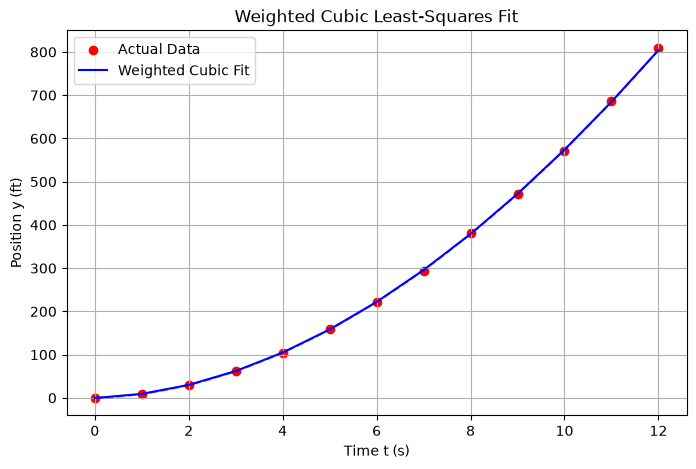

In [9]:
import numpy as np
import matplotlib.pyplot as plt

t = np.arange(13) 
y = np.array([0, 8.8, 29.9, 62.0, 104.7, 159.1, 222.0, 
              294.5, 380.4, 471.1, 571.7, 686.8, 809.2])

w = np.array([1.0, 1.0, 1.0, 0.9, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1])

X = np.column_stack((np.ones_like(t), t, t**2, t**3))

X_weighted = X * w[:, np.newaxis] 
y_weighted = y * w

# 4. 求解加权最小二乘
# 解方程: (WX)^T (WX) beta = (WX)^T (Wy)
beta, residuals, rank, s = np.linalg.lstsq(X_weighted, y_weighted, rcond=None)

b0, b1, b2, b3 = beta

print(" (a) 三次曲线拟合参数 ")
print(f"beta_0 = {b0:.4f}")
print(f"beta_1 = {b1:.4f}")
print(f"beta_2 = {b2:.4f}")
print(f"beta_3 = {b3:.4f}")
print(f"\n拟合函数: y(t) = {b0:.4f} + {b1:.4f}t + {b2:.4f}t^2 + {b3:.4f}t^3")

# 估计 t = 4.5 时的速度
t_eval = 4.5
v_est = b1 + 2 * b2 * t_eval + 3 * b3 * (t_eval**2)

print("\n (b) 速度估计 ")
print(f"在 t = {t_eval} 秒时，预测速度为: {v_est:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(t, y, color='red', label='Actual Data')
plt.plot(t, X @ beta, color='blue', label='Weighted Cubic Fit')
# 标出 t=4.5
t_fit = np.linspace(0, 12, 100)
plt.plot(t_fit, X_fit := (np.column_stack((np.ones_like(t_fit), t_fit, t_fit**2, t_fit**3)) @ beta), 
         'b--', alpha=0.5)
plt.title("Weighted Cubic Least-Squares Fit")
plt.xlabel("Time t (s)")
plt.ylabel("Position y (ft)")
plt.legend()
plt.grid(True)
plt.show()


设计矩阵 $X=[\mathbf{1}\ \mathbf{t}\ \mathbf{t}^2\ \mathbf{t}^3]$（13 行），对 $WX\boldsymbol{\beta}=W\mathbf{y}$ 求最小二乘解：

$$
\boxed{y=-0.2685+3.6095t+5.8576t^2-0.0477t^3}
$$

速度 $v(t)=\beta_1+2\beta_2t+3\beta_3t^2$：

$$
v(4.5)=3.6095+2(5.8576)(4.5)+3(-0.0477)(4.5)^2\approx\boxed{53.43\ \text{（英尺/秒）}}
$$




### 练习6.8 16（高阶傅里叶逼近作图）

**16. 设 $f_4,f_5$ 是方波（练习 10）的四阶、五阶傅里叶逼近。分别画出 $f_4,f_5$ 在 $[0,2\pi]$ 上的图像，并画 $f_5$ 在 $[-2\pi,2\pi]$ 上的图像。**

**解**：由练习 10 的系数 $b_k=\frac{4}{k\pi}$（$k$ 奇）、其余为 $0$：

$$
f_4(t)=\frac4\pi\sin t+\frac4{3\pi}\sin3t,\qquad
f_5(t)=\frac4\pi\sin t+\frac4{3\pi}\sin3t+\frac4{5\pi}\sin5t
$$

（$a_k=0$、偶阶 $b_k=0$，故 $f_4=f_3$、$f_5=f_3+\frac4{5\pi}\sin5t$。）


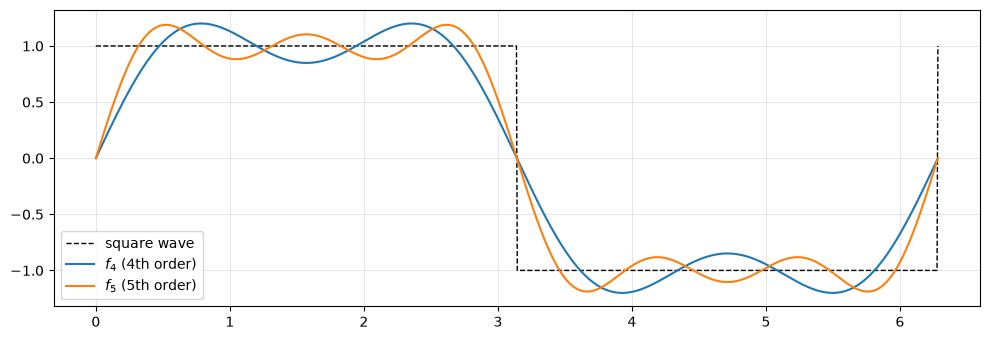

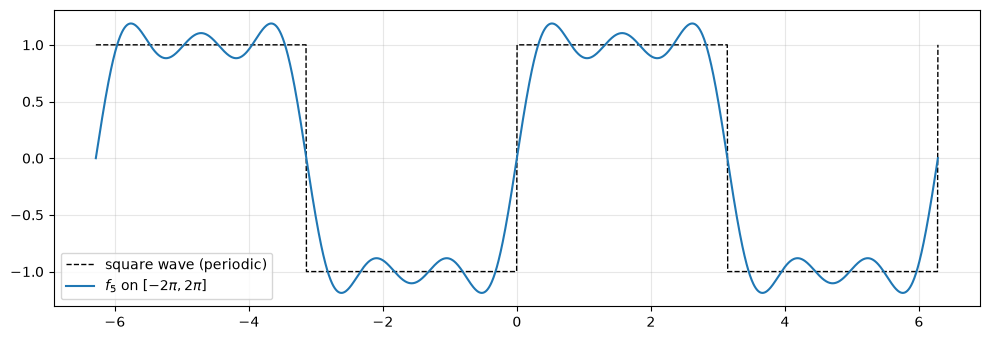

In [11]:


import numpy as np
import matplotlib.pyplot as plt

def square(t):
    return np.where(np.mod(t, 2*np.pi) < np.pi, 1.0, -1.0)

t = np.linspace(0, 2*np.pi, 1000)
f3 = (4/np.pi)*np.sin(t) + (4/(3*np.pi))*np.sin(3*t)
f4 = f3                                   
f5 = f3 + (4/(5*np.pi))*np.sin(5*t)     

plt.figure(figsize=(10, 3.5))
plt.plot(t, square(t), 'k--', lw=1, label='square wave')
plt.plot(t, f4, label='$f_4$ (4th order)')
plt.plot(t, f5, label='$f_5$ (5th order)')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

t2 = np.linspace(-2*np.pi, 2*np.pi, 2000)
f5_2 = (4/np.pi)*np.sin(t2) + (4/(3*np.pi))*np.sin(3*t2) + (4/(5*np.pi))*np.sin(5*t2)
plt.figure(figsize=(10, 3.5))
plt.plot(t2, square(t2), 'k--', lw=1, label='square wave (periodic)')
plt.plot(t2, f5_2, label='$f_5$ on $[-2\\pi,2\\pi]$')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()




> 现象：阶数越高，逼近在间断点附近出现越窄的过冲（Gibbs 现象），但整体更贴近方波；$f_5$ 是周期 $2\pi$ 的奇函数，图像在 $[-2\pi,2\pi]$ 上呈周期性。



## 补充习题 Supplementary Exercises

### 补充 21（Bessel 不等式）

**21. 设 $\{\mathbf{v}_1,\dots,\mathbf{v}_p\}$ 是 $\mathbb{R}^n$ 的标准正交组。对每个 $\mathbf{x}\in\mathbb{R}^n$ 证明（Bessel 不等式）**

$$
\|\mathbf{x}\|^2\ge|\mathbf{x}\cdot\mathbf{v}_1|^2+\cdots+|\mathbf{x}\cdot\mathbf{v}_p|^2
$$

**证**：标准正交组可扩充为 $\mathbb{R}^n$ 的标准正交基 $\{\mathbf{v}_1,\dots,\mathbf{v}_p,\mathbf{v}_{p+1},\dots,\mathbf{v}_n\}$（Gram–Schmidt 可完成扩充）。由 6.2 Theorem 5，$\mathbf{x}$ 可唯一写成

$$
\mathbf{x}=(\mathbf{x}\cdot\mathbf{v}_1)\mathbf{v}_1+\cdots+(\mathbf{x}\cdot\mathbf{v}_n)\mathbf{v}_n
$$

各项两两正交，勾股定理推广得

$$
\|\mathbf{x}\|^2=|\mathbf{x}\cdot\mathbf{v}_1|^2+\cdots+|\mathbf{x}\cdot\mathbf{v}_p|^2+|\mathbf{x}\cdot\mathbf{v}_{p+1}|^2+\cdots+|\mathbf{x}\cdot\mathbf{v}_n|^2
$$

丢掉后 $n-p$ 个非负项即得不等式。



### 补充 25（Householder 矩阵）

**25. Householder 矩阵（初等反射）$Q=I-2\mathbf{u}\mathbf{u}^T$，其中 $\mathbf{u}$ 是单位向量。证明 $Q$ 正交；证明 $Q\mathbf{v}=-\mathbf{v}$（$\mathbf{v}\in\operatorname{Span}\{\mathbf{u}\}$）、$Q\mathbf{v}=\mathbf{v}$（$\mathbf{v}\in(\operatorname{Span}\{\mathbf{u}\})^\perp$）。**

**证明**：

$\mathbf{u}^T\mathbf{u}=1$：

$$
Q^TQ=(I-2\mathbf{u}\mathbf{u}^T)^T(I-2\mathbf{u}\mathbf{u}^T)=(I-2\mathbf{u}\mathbf{u}^T)(I-2\mathbf{u}\mathbf{u}^T)
$$

$$
=I-4\mathbf{u}\mathbf{u}^T+4\mathbf{u}(\mathbf{u}^T\mathbf{u})\mathbf{u}^T=I-4\mathbf{u}\mathbf{u}^T+4\mathbf{u}\mathbf{u}^T=I
$$

故 $Q$ 正交。

$\mathbf{v}=c\mathbf{u}$：

$$ Q\mathbf{v}=\mathbf{v}-2\mathbf{u}(\mathbf{u}^T\mathbf{v})=\mathbf{v}-2c\mathbf{u}(\mathbf{u}^T\mathbf{u})=\mathbf{v}-2\mathbf{v}=-\mathbf{v}$$

$\mathbf{v}\perp\mathbf{u}$：

$$\mathbf{u}^T\mathbf{v}=0,Q\mathbf{v}=\mathbf{v}-\mathbf{0}=\mathbf{v}$$

> 结论：$\operatorname{Span}\{\mathbf{u}\}$ 是特征值 $-1$ 的特征空间，$(\operatorname{Span}\{\mathbf{u}\})^\perp$ 是特征值 $1$ 的特征空间——$Q$ 是关于超平面 $(\operatorname{Span}\{\mathbf{u}\})^\perp$ 的镜面反射。计算机 QR 分解常用一串这样的反射把 $A$ 化为上三角。



### 补充 30（Rayleigh 商）

**30. 已知 $A$ 的近似特征向量 $\mathbf{v}$，把 $A\mathbf{v}=\lambda\mathbf{v}$ 看成 $V\lambda=\mathbf{b}$（$V=\mathbf{v}$ 视为 $n\times1$ 矩阵，$\mathbf{b}=A\mathbf{v}$），求 $\lambda$ 的最小二乘估计。**

**解**：正规方程 $V^TV\lambda=V^T\mathbf{b}$：

$$
(\mathbf{v}^T\mathbf{v})\lambda=\mathbf{v}^T(A\mathbf{v})\ \Longrightarrow\ \boxed{\lambda=\frac{\mathbf{v}\cdot A\mathbf{v}}{\mathbf{v}\cdot\mathbf{v}}=\frac{\mathbf{v}^TA\mathbf{v}}{\mathbf{v}^T\mathbf{v}}}
$$

这个估计称为 **Rayleigh 商（Rayleigh quotient）**。

> 备注：若 $\mathbf{v}$ 恰是特征向量，则 $\lambda$ 精确等于对应特征值。Rayleigh 商是幂法/QR 算法估计特征值的基础。



**瑞利商:代数估计 & 几何投影**

瑞利商 $R(\mathbf{x}) = \frac{\mathbf{x}^T A\mathbf{x}}{\mathbf{x}^T \mathbf{x}}$ 在教材中出现了两次，代表了两种不同的视角。

**第 5 章视角：代数与数值估计（5.8 节）**
*   **前提**：使用幂法得到了一个**近似**的特征向量 $\mathbf{x}$。
*   **推导**：假设 $A\mathbf{x} = \lambda \mathbf{x}$ 成立，两边左乘 $\mathbf{x}^T$，直接移项解出 $\lambda = R(\mathbf{x})$。
*   **侧重点**：**数值计算工具**。对于实对称矩阵，用瑞利商估计出的特征值，其精度比直接用幂法缩放系数 $\mu_k$ **高一倍**。

**第 6 章视角：几何与最小二乘（补充题 30）**
*   **前提**：已知近似特征向量 $\mathbf{v}$，此时方程 $A\mathbf{v} = \lambda \mathbf{v}$ 严格来说是**无解**的（因为 $\mathbf{v}$ 不完美，$A\mathbf{v}$ 与 $\mathbf{v}$ 不共线）。
*   **推导**：把 $A\mathbf{v} = \lambda \mathbf{v}$ 看作未知数为标量 $\lambda$ 的超定方程组（$V\lambda = \mathbf{b}$）。套用最小二乘的正规方程 $V^T V \lambda = V^T \mathbf{b}$，因为 $V$ 只有一列，解出来依然是 $R(\mathbf{v})$。
*   **侧重点**：**几何上的最佳逼近**。它代表向量 $A\mathbf{v}$ 在 $\mathbf{v}$ 所在直线上的**正交投影系数**，让误差 $\|A\mathbf{v} - \lambda\mathbf{v}\|^2$ 最小。



第 5 章教**怎么算（实用）**，第 6 章用刚学的正交投影和最小二乘，讲**为什么对（原理）**。代数的直接替换，本质上就是在做几何上的误差最小化投影。


### 补充 31（四个基本子空间的关系）

**31. 证明 $\operatorname{Row}A=(\operatorname{Nul}A)^\perp$，$\operatorname{Col}A=(\operatorname{Nul}A^T)^\perp$。**

**a.** 证 $\operatorname{Row}A\subseteq(\operatorname{Nul}A)^\perp$：

取 $\mathbf{x}\in\operatorname{Row}A$，则 $\mathbf{x}=A^T\mathbf{y}$（某 $\mathbf{y}$）。对任意 $\mathbf{u}\in\operatorname{Nul}A$：

$$
\mathbf{x}\cdot\mathbf{u}=(A^T\mathbf{y})\cdot\mathbf{u}=(A^T\mathbf{y})^T\mathbf{u}=\mathbf{y}^TA\mathbf{u}=\mathbf{y}^T\mathbf{0}=0
$$

故 $\mathbf{x}\perp\mathbf{u}$。

**b.** 设 $\operatorname{rank}A=r$。秩-零度定理：$\dim\operatorname{Nul}A=n-r$；由 6.3 练习 32 的维数互补公式 $\dim W+\dim W^\perp=n$，$\dim(\operatorname{Nul}A)^\perp=n-(n-r)=r$。而 $\operatorname{Row}A$ 的维数也是 $r$，且 $\operatorname{Row}A\subseteq(\operatorname{Nul}A)^\perp$——维数相同的包含关系必为相等：

$$
\operatorname{Row}A=(\operatorname{Nul}A)^\perp.\ 
$$

**c.** 把 a、b 应用于 $A^T$：$\operatorname{Row}A^T=(\operatorname{Nul}A^T)^\perp$，而 $\operatorname{Row}A^T=\operatorname{Col}A$。

则有
$$
\operatorname{Col}A=(\operatorname{Nul}A^T)^\perp
$$

> 意义：四个基本子空间两两正交互补——$\mathbb{R}^n=\operatorname{Row}A\oplus\operatorname{Nul}A$，$\mathbb{R}^m=\operatorname{Col}A\oplus\operatorname{Nul}A^T$。



### 补充 32

**32. 解释为什么 $A\mathbf{x}=\mathbf{b}$ 有解，当且仅当 $\mathbf{b}$ 与 $A^T\mathbf{x}=\mathbf{0}$ 的所有解正交。**

**解**：$A\mathbf{x}=\mathbf{b}$ 相容 $\iff\mathbf{b}\in\operatorname{Col}A$。由 6.1 Theorem 3，$(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T$；由补充 31（或 $(\operatorname{Col}A)^{\perp\perp}=\operatorname{Col}A$），

$$
\mathbf{b}\in\operatorname{Col}A\iff\mathbf{b}\in(\operatorname{Nul}A^T)^\perp
$$

即 $\mathbf{b}$ 与 $\operatorname{Nul}A^T$（$A^T\mathbf{x}=\mathbf{0}$ 的解集）中每个向量正交。



### 补充 34（Schur 分解）

**34. a. 设 $A=PDP^{-1}$ 可对角化。证明 $P$ 有 QR 分解，并用它构造 $A$ 的（实）Schur 分解 $A=URU^T$（$U$ 正交、$R$ 上三角）。**

**证**：$P$ 的列线性无关（$P$ 可逆），由 6.4 Theorem 12，$P=QR$（$Q$ 列标准正交的方阵即正交矩阵，$R$ 上三角可逆）。于是

$$
A=PDP^{-1}=QRDR^{-1}Q^T=Q(RDR^{-1})Q^T
$$

令 $U=Q$，$R_1=RDR^{-1}$。$D$ 是对角阵、$R$ 上三角可逆，故 $RDR^{-1}$ 仍是**上三角**。所以 $A=UR_1U^T$ 是实 Schur 分解。



**b. 求 $A=\begin{bmatrix}-2&12\\-1&5\end{bmatrix}$ 的实 Schur 分解。**

**解**：特征值：$\operatorname{tr}=3$，$\det=(-2)(5)-(12)(-1)=2$，$\lambda^2-3\lambda+2=0\Rightarrow\lambda=1,2$。特征向量：$\lambda=1$ 时 $(A-I)\mathbf{v}=\mathbf{0}\Rightarrow\mathbf{v}_1=(4,1)$；$\lambda=2$ 时 $\mathbf{v}_2=(3,1)$。故

$$
P=\begin{bmatrix}4&3\\1&1\end{bmatrix},\qquad D=\begin{bmatrix}1&0\\0&2\end{bmatrix}
$$

对 $P$ 做 QR：$Q=\dfrac1{\sqrt{17}}\begin{bmatrix}4&-1\\1&4\end{bmatrix}$，$R=\begin{bmatrix}\sqrt{17}&13/\sqrt{17}\\0&1/\sqrt{17}\end{bmatrix}$。于是

$$
R_1=RDR^{-1}=\begin{bmatrix}1&13\\0&2\end{bmatrix}
$$

$$
\boxed{A=\left(\frac1{\sqrt{17}}\begin{bmatrix}4&-1\\1&4\end{bmatrix}\right)\begin{bmatrix}1&13\\0&2\end{bmatrix}\left(\frac1{\sqrt{17}}\begin{bmatrix}4&-1\\1&4\end{bmatrix}\right)^T}
$$


**c. 求 $A=\begin{bmatrix}2&2&1\\1&3&1\\1&2&2\end{bmatrix}$ 的实 Schur 分解。**

**解**：特征多项式 $\lambda^3-7\lambda^2+11\lambda-5=(\lambda-5)(\lambda-1)^2$，特征值 $5,1,1$。特征向量：$\lambda=5$：$\mathbf{v}_1=(1,1,1)$；$\lambda=1$：$\mathbf{v}_2=(-2,1,0)$，$\mathbf{v}_3=(-1,0,1)$。故

$$
P=\begin{bmatrix}1&-2&-1\\1&1&0\\1&0&1\end{bmatrix},\qquad D=\begin{bmatrix}5&0&0\\0&1&0\\0&0&1\end{bmatrix}
$$

对 $P$ 做 Gram–Schmidt 得 $Q$，计算 $R_1=RDR^{-1}$

$$
Q=\begin{bmatrix}\sqrt3/3&-5\sqrt{42}/42&-\sqrt{14}/14\\\sqrt3/3&2\sqrt{42}/21&-\sqrt{14}/7\\\sqrt3/3&\sqrt{42}/42&3\sqrt{14}/14\end{bmatrix},\qquad
R_1=\begin{bmatrix}5&2\sqrt{14}/7&-\sqrt{42}/7\\0&1&0\\0&0&1\end{bmatrix}
$$

$$
\boxed{A=QR_1Q^T}
$$





### 补充 37（条件数）

**37. 设 $A=\begin{bmatrix}7&-6&-4&1\\-5&1&0&-2\\10&9&7&-3\\19&7&7&1\end{bmatrix}$，$\mathbf{b}=\begin{bmatrix}.100\\2.888\\-1.404\\1.462\end{bmatrix}$，$\Delta\mathbf{b}=10^{-4}\begin{bmatrix}.49\\-1.28\\5.78\\8.04\end{bmatrix}$。解 $A\mathbf{x}=\mathbf{b}$ 与 $A(\Delta\mathbf{x})=\Delta\mathbf{b}$，验证不等式**
$$
\frac{\|\Delta\mathbf{x}\|}{\|\mathbf{x}\|}\le\operatorname{cond}(A)\cdot\frac{\|\Delta\mathbf{b}\|}{\|\mathbf{b}\|}
$$



**解**：


In [14]:
import numpy as np

A = np.array([
    [7, -6, -4, 1],
    [-5, 1, 0, -2],
    [10, 11, 7, -3],
    [19, 9, 7, 1]
], dtype=float)

b = np.array([0.100, 2.888, -1.404, 1.462])
delta_b = 1e-4 * np.array([0.49, -1.28, 5.78, 8.04])

# 求解 x 和 Delta_x
x = np.linalg.solve(A, b)
delta_x = np.linalg.solve(A, delta_b)

# 计算各部分的norm
norm_b = np.linalg.norm(b)
norm_delta_b = np.linalg.norm(delta_b)
norm_x = np.linalg.norm(x)
norm_delta_x = np.linalg.norm(delta_x)

# 计算相对误差
rel_change_b = norm_delta_b / norm_b
rel_change_x = norm_delta_x / norm_x

# 计算 A 的条件数
cond_A = np.linalg.cond(A, p=2)

print(f"x = {np.round(x, 4)}")
print(f"Δx = {delta_x}\n")

print(f"||b|| = {norm_b:.6f}")
print(f"||Δb|| = {norm_delta_b:.6e}")
print(f"b 的相对变化率: {rel_change_b:.6e}\n")

print(f"||x|| = {norm_x:.6f}")
print(f"||Δx|| = {norm_delta_x:.6e}")
print(f"x 的相对变化率: {rel_change_x:.6e}\n")

print(f"cond(A) = {cond_A:.2f}")
print(f"不等式右边 (条件数 × b的变化率) = {cond_A * rel_change_b:.6e}")

# 比较验证
assert rel_change_x <= cond_A * rel_change_b, "不等式不成立！"
print(f"\nx 的相对误差 ({rel_change_x:.4e}) ≤ 放大上限 ({cond_A * rel_change_b:.4e})")

x = [   -8.642 -1730.054  2368.716  -844.866]
Δx = [ 3.00e-05  1.40e-04 -1.55e-04  5.90e-05]

||b|| = 3.529760
||Δb|| = 9.996424e-04
b 的相对变化率: 2.832041e-04

||x|| = 3052.503165
||Δx|| = 2.191027e-04
x 的相对变化率: 7.177805e-08

cond(A) = 23682.93
不等式右边 (条件数 × b的变化率) = 6.707102e+00

x 的相对误差 (7.1778e-08) ≤ 放大上限 (6.7071e+00)


**第六章补充完成了“为什么条件数能衡量误差放大倍数”的严格数学证明**。


**第二章：给出“定义”与“现象”**

第二章（2.3节及练习50-51）定义了条件数 $\kappa(A) = \|A\|\|A^{-1}\|$，然后通过希尔伯特矩阵的实验展示了一个**现象**：当条件数极大时，微小的舍入误差会让计算结果彻底崩溃。此时并没有严格证明“误差到底是怎么被放大的”。


第六章补充题给出了误差不等式：
$$
 \frac{\|\Delta \mathbf{x}\|}{\|\mathbf{x}\|} \le \text{cond}(A) \cdot \frac{\|\Delta \mathbf{b}\|}{\|\mathbf{b}\|} 
$$
**这个不等式说明条件数就是误差放大倍数**——给出了数学上的严格上界。



如果用正规方程（$A^TA$），误差放大倍数会从 $\kappa(A)$ 变成 $\kappa(A)^2$；又因为正交矩阵不改变向量长度，所以用 QR 分解（定理15）可以完美避开条件数平方的爆炸。

**为什么正交矩阵 $Q$ 的条件数永远是 1？**

条件数定义：$\kappa(Q) = \|Q\| \cdot \|Q^{-1}\|$

*   **性质 1**：正交矩阵的逆等于转置，即 $Q^{-1} = Q^T$。所以 $\kappa(Q) = \|Q\| \cdot \|Q^T\|$。
*   **性质 2**：在 2-范数下，矩阵的范数等于它最大的拉伸倍数。因为正交变换不改变向量长度，所以 $\|Q\| = 1$。同理 $\|Q^T\| = 1$。
*   **结论**：$\kappa(Q) = 1 \times 1 = \mathbf{1}$。
---
**为什么 $\kappa(A^TA) = \kappa(A)^2$？**

条件数定义：$\kappa(A^TA) = \|A^TA\| \cdot \|(A^TA)^{-1}\|$

*  根据 2-范数性质，$\|A^TA\| = \|A\|^2$。
*  逆的展开是 $(A^TA)^{-1} = A^{-1}(A^T)^{-1}$。所以它的范数 $\|(A^TA)^{-1}\| = \|A^{-1}\|^2$。
*   **第三步（相乘）**：
$$
 \kappa(A^TA) = \|A\|^2 \cdot \|A^{-1}\|^2 = (\|A\| \cdot \|A^{-1}\|)^2 = \mathbf{\kappa(A)^2} 
$$

---
**$R$ 的条件数为什么等于 $A$ 的条件数**

已知条件数定义为 $\kappa(M) = \|M\| \cdot \|M^{-1}\|$，且 $A = QR$。

$$
 \|A\| = \|QR\| 
$$
因为 $Q$ 是正交矩阵（不改变长度），所以 $\|Q\| = 1$。因此：
$$
 \|A\| = \|Q\| \cdot \|R\| = 1 \cdot \|R\| = \|R\| 
$$

$$
 A^{-1} = (QR)^{-1} = R^{-1}Q^{-1} 
$$
因为 $Q$ 是正交阵，所以 $Q^{-1} = Q^T$。代入取范数：
$$
 \|A^{-1}\| = \|R^{-1}Q^T\| \le \|R^{-1}\| \cdot \|Q^T\| 
$$
同样因为 $\|Q^T\| = 1$，所以：
$$
 \|A^{-1}\| = \|R^{-1}\| 
$$

将 $\|R\|$ 和 $\|R^{-1}\|$ 代回 $R$ 的条件数公式：
$$
 \kappa(R) = \|R\| \cdot \|R^{-1}\| = \|A\| \cdot \|A^{-1}\| = \mathbf{\kappa(A)} 
$$

---

在 $A = QR$ 中，$Q$ 只改变向量的方向（不拉伸，条件数为 1），而 $R$ 负责拉伸与压缩（上三角矩阵）。
所以，整个矩阵 $A$ 到底把空间拉伸得有多扁（病态程度），**全靠 $R$ 来体现**。$R$ 完美继承了 $A$ 的拉伸比例，因此它们的条件数完全一致。这就是为什么用 QR 分解解方程，能保住原矩阵的精度。




## 总结

| 节 | 核心概念 | 关键公式 / 定理 |
|---|---|---|
| 6.1 | 内积、长度、距离、正交、正交补 | 内积 $\mathbf{u}\cdot\mathbf{v}=\mathbf{u}^T\mathbf{v}$；长度 $\|\mathbf{u}\|=\sqrt{\mathbf{u}\cdot\mathbf{u}}$；距离 $\operatorname{dist}(\mathbf{u},\mathbf{v})=\|\mathbf{u}-\mathbf{v}\|$；Pythagoras：$\|\mathbf{u}+\mathbf{v}\|^2=\|\mathbf{u}\|^2+\|\mathbf{v}\|^2 \iff \mathbf{u}\perp\mathbf{v}$；**Thm 3**：$(\operatorname{Row}A)^\perp=\operatorname{Nul}A,\;(\operatorname{Col}A)^\perp=\operatorname{Nul}A^T$ |
| 6.2 | 正交组、标准正交组、正交矩阵 | **Thm 4**：非零正交组线性无关；**Thm 5**：$W$ 的标准正交基 $\{\mathbf{u}_1,\dots,\mathbf{u}_p\}$ 下 $\mathbf{y}=(\mathbf{y}\cdot\mathbf{u}_1)\mathbf{u}_1+\cdots+(\mathbf{y}\cdot\mathbf{u}_p)\mathbf{u}_p$；**Thm 6**：$U^TU=I \iff$ 列标准正交；**Thm 7**：$(U\mathbf{x})\cdot(U\mathbf{y})=\mathbf{x}\cdot\mathbf{y},\ \|U\mathbf{x}\|=\|\mathbf{x}\|$ |
| 6.3 | 正交投影、最佳逼近 | **Thm 8（正交分解）**：$\mathbf{y}=\hat{\mathbf{y}}+\mathbf{z}$，$\hat{\mathbf{y}}\in W,\ \mathbf{z}\in W^\perp$；**Thm 9（最佳逼近）**：$\hat{\mathbf{y}}=\operatorname{proj}_W\mathbf{y}$ 是 $W$ 中离 $\mathbf{y}$ 最近的点；**Thm 10**：$\operatorname{proj}_W\mathbf{y}=UU^T\mathbf{y}$ |
| 6.4 | Gram–Schmidt 正交化、QR 分解 | **Thm 11**：$\mathbf{v}_k=\mathbf{x}_k-\sum_{j<k}\frac{\mathbf{x}_k\cdot\mathbf{v}_j}{\mathbf{v}_j\cdot\mathbf{v}_j}\mathbf{v}_j$；**Thm 12**：$A=QR$，$Q$ 列标准正交、$R$ 上三角可逆 |
| 6.5 | 最小二乘问题 | **Thm 13**：$\hat{\mathbf{x}}$ 是最小二乘解 $\iff A^TA\hat{\mathbf{x}}=A^T\mathbf{b}$（正规方程）；**Thm 14**：$A$ 列线性无关 $\iff A^TA$ 可逆 $\iff \hat{\mathbf{x}}=(A^TA)^{-1}A^T\mathbf{b}$ 唯一；**Thm 15**：$A=QR \Rightarrow \hat{\mathbf{x}}=R^{-1}Q^T\mathbf{b}$ |
| 6.6 | 机器学习线性模型 | 设计矩阵 $X$、观测 $\mathbf{y}$：正规方程 $X^T X \boldsymbol{\beta} = X^T\mathbf{y}$；最小二乘预测 $\hat{\mathbf{y}}=X\hat{\boldsymbol{\beta}}$；QR 数值稳定解法；$SS(T)=SS(R)+SS(E)$ |
| 6.7 | 一般内积空间 | 内积公理（对称/线性/正定）；加权内积、积分内积 $\langle f,g\rangle=\int_a^b f(t)g(t)\,dt$；**Thm 16（Cauchy–Schwarz）**：$\vert \langle\mathbf{u},\mathbf{v}\rangle \vert \le \Vert \mathbf{u} \Vert \Vert \mathbf{v} \Vert$；**Thm 17（三角不等式）**：$\Vert \mathbf{u}+\mathbf{v} \Vert \le \Vert \mathbf{u} \Vert + \Vert \mathbf{v} \Vert$ |
| 6.8 | 内积空间的应用 | 加权最小二乘：$\min\|W\mathbf{y}-WX\boldsymbol{\beta}\|$；趋势分析：正交多项式 + 系数 $c_i=\langle g,p_i\rangle/\langle p_i,p_i\rangle$；傅里叶系数 $a_k=\frac1\pi\int f\cos kt$，$b_k=\frac1\pi\int f\sin kt$，$f_n=\frac{a_0}{2}+\sum(a_k\cos kt+b_k\sin kt)$ |

**四个基本子空间（练习 6.1 42 与补充 31）**

$$
\boxed{\operatorname{Row}A=(\operatorname{Nul}A)^\perp,\qquad \operatorname{Col}A=(\operatorname{Nul}A^T)^\perp}
$$

**最小二乘三大解法（ 6.5 练习 11、33–34）**

1. 正规方程：$A^TA\hat{\mathbf{x}}=A^T\mathbf{b}$；
2. QR：$A=QR \Rightarrow \hat{\mathbf{x}}=R^{-1}Q^T\mathbf{b}$（数值更稳定）；
3. 几何视角：$\hat{\mathbf{x}}$ 使 $A\hat{\mathbf{x}}=\operatorname{proj}_{\operatorname{Col}A}\mathbf{b}$，残差 $\mathbf{b}-A\hat{\mathbf{x}}\in(\operatorname{Col}A)^\perp$。
